package imports

In [1]:
#for reading files
import glob
import tifffile

#math computation and data organization
import numpy as np
import math
import scipy
from scipy.ndimage import binary_erosion, binary_fill_holes
from scipy import optimize
from scipy.optimize import curve_fit
import pandas as pd

# For loading bars
from tqdm.notebook import tqdm as tqdm

#For image plotting
import skimage.io

#For identifying aster center
from skimage.filters import threshold_otsu, gaussian, threshold_mean
from skimage.measure import regionprops
import cv2

#for fitting
from lmfit import minimize, Parameters, fit_report

#for image registration
from skimage.registration import phase_cross_correlation
import os

#Matplotlib plotting packages
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import patches
from matplotlib import gridspec

import seaborn as sns
sns.set_context("poster")
sns.set_style("ticks")

#Movie
import celluloid as cell
import matplotlib.animation as animation

#for saving data
import csv
import h5py

#custom analysis packages
import aster_packages as ap #### commented out 20241114 since lucida fonts are not installed...

# Thing to enable lovely parallelization
import concurrent.futures

# Enable repeat from itertools for parallel
import itertools

#time elements for testing runtimes and using todays date
import time
from datetime import datetime

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # Use TrueType fonts for editable text in PDFs

set style conventions

In [2]:
######### gabe hacky styling to emulate some of PBoC Phillips lab style conventions, however hacky. tries to make easier for nigel++
## Styling
import matplotlib
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context("poster")
# sns.set_style('ticks')

import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Set the property to save figures with text as text, not paths
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# default good PBoC colors
baseBlendColor=(224/255, 219/255, 209/255,1) # default background for plots
contrastColor=(209/255, 193/255, 171/255,1) # slightly darker tan for contrasts, e.g. in inset boxes
yellowTanHighlightBoxColor='#FEF0C6'
goodGreyGreenArrowColor='#CCD4C9'

### Griffin style invocation

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.path import Path
from matplotlib.patches import BoxStyle
from matplotlib.offsetbox import AnchoredText

def plotting_style(grid=False):
    """
    Sets the style to the publication style. To instantiate, simply call
    plotting_style() at the beginning of your script or notebook to force
    all matplotlib plots to adopt the scheme.

    Parameters
    ----------
    grid: bool
      If True, plots will have a thin, white grid in the background. Default
      is False.

    Returns
    -------
    colors: dict
      Returns a dictionary of the standard PBoC 2e color palette.
    """
    rc = {'axes.facecolor': '#E3DCD0',
#               'axes.spines.top': False,
#               'axes.spines.right': False,
#               'axes.spines.left': False,  # Ensure left spine is present
#               'axes.spines.bottom': False,  # Ensure bottom spine is present
#               'axes.spines.left': False, #{'color': '#E3DCD0', 'linewidth': 1.5},  # Set the spine color to the background color
#               'axes.spines.bottom': False, #{'color': '#E3DCD0', 'linewidth': 1.5},  # Set the spine color to the background color
          #'font.family': '/usr/share/fonts/truetype/LucidaSansOT.otf', #'LucidaSansOT.otf',
          'grid.linestyle': '-',
          'grid.linewidth': 0.5,
          'grid.alpha': 0.75,
          'grid.color': '#ffffff',
          'axes.grid': grid,
          'ytick.direction': 'in',
          'xtick.direction': 'in',
          'xtick.gridOn': grid,
          'ytick.gridOn': grid,
#               'ytick.major.width':8,
#               'xtick.major.width':8,
#               'ytick.major.size': 8,
#               'xtick.major.size': 8,
          'mathtext.fontset': 'stixsans',
          'mathtext.sf': 'sans',
          'legend.frameon': True,
          'legend.facecolor': '#FFEDCE',
          'figure.dpi': 150,
          'xtick.color': 'k',
          'ytick.color': 'k'
         }
    plt.rc('text.latex', preamble=r'\usepackage{sfmath}')
    plt.rc('mathtext', fontset='stixsans', sf='sans')
    sns.set_style('darkgrid', rc=rc)
    return color_palette()

def color_palette():
    """
    Returns a dictionary of the PBOC color palette
    """
    return {'green': '#7AA974', 'light_green': '#BFD598',
              'pale_green': '#DCECCB', 'yellow': '#EAC264',
              'light_yellow': '#F3DAA9', 'pale_yellow': '#FFEDCE',
              'blue': '#738FC1', 'light_blue': '#A9BFE3',
              'pale_blue': '#C9D7EE', 'red': '#D56C55', 'light_red': '#E8B19D',
              'pale_red': '#F1D4C9', 'purple': '#AB85AC',
              'light_purple': '#D4C2D9', 'dark_green':'#7E9D90', 'dark_brown':'#905426'}

def titlebox(
    ax, text, color, bgcolor=None, size=8, boxsize=0.1, pad=0.05, **kwargs
):
    """
    Sets a colored title box above the plot, spanning the entire plot width.

    Parameters
    ----------
    ax : matplotlib axis object
      The axis on which you want to add the titlebox.
    text: str
      The title tect
    bgcolor: str or None
      The background color of the title box. Default is no color (blank).
    size:  int
      Size of the text font
    boxsize: float [0, 1]
      Fraction of the total plot height to be occupied by the box. Default is 10% (0.1).
    pad: float
      The padding space between the title box and the top of the plot.

    """
    boxsize=str(boxsize * 100)  + '%'
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("top", size=boxsize, pad=pad)
    cax.get_xaxis().set_visible(False)
    cax.get_yaxis().set_visible(False)
    cax.spines["top"].set_visible(False)
    cax.spines["right"].set_visible(False)
#     cax.spines["bottom"].set_visible(False)
#     cax.spines["left"].set_visible(False)

#     cax.spines["bottom"].set_visible(True)
#     cax.spines["left"].set_visible(True)
#     cax.spines["left"].set_color("white")
#     cax.spines["bottom"].set_color("white")
#     cax.spines["bottom"].set_color("white")

#     cax.set_ticks_position('both')  # Adding ticks to both top and bottom
#     cax.yaxis.set_tick_params(direction='in', which='both', color='white')  # The bottom will maintain the default of 'out'


    plt.setp(cax.spines.values(), color=color)
    if bgcolor != None:
        cax.set_facecolor(bgcolor)
    else:
        cax.set_facecolor("white")
    at = AnchoredText(text, loc=10, frameon=False, prop=dict(size=size, color=color))
    cax.add_artist(at)


### Now actually call it
plotting_style()

import matplotlib.patheffects as pe
matplotlib.rcParams['axes.autolimit_mode'] = 'data'

# Import functions to read and parse h5py saved aster data

In [3]:
def read_h5py(path_name, excludes=[], includes=[]):
    # Glob for directory parsing to get all .h5 files in the specified path
    h5files = glob.glob(path_name + '/*.h5')
    for excl in excludes:
        h5files=[file for file in h5files if excl not in file]
    for incl in includes:
        h5files=[file for file in h5files if incl in file]

    print(len(h5files))
        
    #print("HDF5 files found:", h5files)
    
    # Dictionary to store arrays from each file
    all_data = {}
    
    for file in h5files:
        file_data = []  # List to hold datasets for the current file
        
        with h5py.File(file, 'r') as h5file:
            def load_data(name, obj):
                if isinstance(obj, h5py.Dataset):
                    file_data.append(obj[:])  # Append dataset as a NumPy array
            
            # Visit all datasets in the file and load them into file_data
            h5file.visititems(load_data)
        
        #slice by 8 since the date has 8 didgits
        field_name = file.split('.h5')[0].split('tif')[-1][15:] #BRO, 15 is the number of digits in how we save datetime -> 20241114_201131 (formerly we had 8 since we didnt include time)
        #print(file + '\n')
        #print(field_name+ '\n')
            
        # Add this file's data to all_data with the filename as the key
        all_data[field_name] = file_data[0]
        
        
    return all_data

In [4]:
def makeImFromValsList(valuesList, mask_coords, imshape):
    """ valuesList: numTimepoints x numValues, such that valuesList[t,:] is the list of values we populate in the returned image/array
        mask_coords: tuple of length 2; the first entry is 1d array of rowNums and the second entry is 1d array of colNums, of length = numValues (defined in mask)
        imshape: numImgRows x numImgCols.
        
        Returns imgArrayTotal = (numTimepoints x numImgRows x numImgCols) array where things are zero when outside the mask and otherwise populated by the provided valuesList in appropriate positions.
    """
    imgArrayTotal = np.zeros((len(valuesList), imshape[0], imshape[1]))
    for t in range(len(valuesList)):
        imgArrayTotal[t,mask_coords[0], mask_coords[1]]=valuesList[t,:]
    
    return imgArrayTotal

In [5]:
import xml.etree.ElementTree as ET
def grabxml(annotPath):
    tree = ET.parse(annotPath)  # Replace with actual filename
    root = tree.getroot()
    
    # --- Step 1: Extract task info indexed by task ID ---
    task_data = {}
    for task in root.findall(".//task"):
        task_id = task.find("id").text
        task_data[task_id] = {
            "task_start_frame": int(task.find("start_frame").text),
            "task_stop_frame": int(task.find("stop_frame").text),
            "task_source": task.find("source").text
        }
    
    # --- Step 2: Extract ellipse data inside each track ---
    all_ellipses = []
    
    for track in root.findall("track"):
        track_attrs = track.attrib
        task_id = track_attrs.get("task_id")
        
        # Get task info by task_id
        task_info = task_data.get(task_id, {})
    
        for ellipse in track.findall("ellipse"):
            ellipse_attrs = ellipse.attrib
    
            row = {
                **track_attrs,
                **ellipse_attrs,
                **task_info
            }
    
            all_ellipses.append(row)
    
    # --- Step 3: Convert to DataFrame ---
    annotdf = pd.DataFrame(all_ellipses)
    
    # Optional: convert numeric columns
    for col in ['frame', 'cx', 'cy', 'rx', 'ry', 'z_order', 'task_start_frame', 'task_stop_frame']:
        if col in annotdf.columns:
            annotdf[col] = pd.to_numeric(annotdf[col], errors='coerce')

    return annotdf

In [6]:
def findmp4NameFromGname(gname):
    date = gname.split('assay_')[1].split('/')[0]
    rep = gname.split('/')[-1].split('_MMStack')[0].split('A81D_')[1]
    pos = gname.split('/')[-1].split('MMStack_')[1].split('.ome')[0]
    if 'uM_Ncd' in gname:
        mot = gname.split('uM_Ncd')[0].split('_')[-1]
    elif 'uM_NCD' in gname:
        mot = gname.split('uM_NCD')[0].split('_')[-1]
    atp = gname.split('ATP')[0].split('_')[-1]
    
    mp4name = date+'_r'+rep+'_'+pos+'_mot'+mot+'_atp'+atp+'.mp4'
    return mp4name

In [7]:
def cvatCentandRad(gname, annotPath, imshape):
    annotdf = grabxml(annotPath)
    #for motor sweep
    source = findmp4NameFromGname(gname)
    # #for ATP sweep
    # source = findATPSweepmp4NameFromGname(gname)
    
    annotdf_subset = annotdf[annotdf['task_source']==source]
 
    cvatframes = np.array(annotdf_subset['frame']-annotdf_subset['frame'].max() + annotdf_subset['task_stop_frame'])
    firstkeyframe = cvatframes.min()
    
    firstFramesCenters = np.array([[imshape[1]/2,imshape[0]/2]]*firstkeyframe)
    cvatCenters =  np.array([annotdf_subset['cx'], annotdf_subset['cy']]).T
    centers = np.concat((firstFramesCenters, cvatCenters))
    
    firstFramesLengths = np.array([[np.nan,np.nan]]*firstkeyframe)
    cvatAxesLengths = np.array([annotdf_subset['rx'], annotdf_subset['ry']]).T
    axesLengths = np.concat((firstFramesLengths, cvatAxesLengths))
     
    if len(centers) > 300:
        centers = centers[:300]
        axesLengths = axesLengths[:300]
    return centers, axesLengths

In [8]:
def find_contour(mask):
    #Find contours of binary image
    contours, heirarchy = cv2.findContours(mask.astype(np.uint8), 1, 2)
    #iterate through contours (for most connected region)
    max_area = 0
    max_index = None
    for j, contour in enumerate(contours):
        area = cv2.contourArea(contour)
        if area > max_area:
            max_area = area
            max_index = j

    #Find the coordinates of the illumination pattern contour
    cnt = contours[max_index]
    cnt = np.array(cnt)
    cnt = np.squeeze(cnt)
    return cnt

In [9]:
def min_radius(mango_mask, centers):
    mango_skin_coords = find_contour(mango_mask)
    #reshapes stuff and broadcasts to do subtraction
    dists = np.sqrt(np.sum((mango_skin_coords[:, np.newaxis, :] - centers[np.newaxis, :, :])**2, axis=2))
    #find the minimum distance
    min_dist = np.min(dists)
    # #find the time and position corresponding to the minimum distance
    # min_dist_point, min_dist_time = np.where(dists==min_dist)
    # #find the coordinate of the minimimum distance
    # min_dist_coord = mango_skin_coords[min_dist_point]
    return min_dist

In [10]:
def spaceTimeAvg(imgArray, numTimesWindow, spatialBlock, mode='valid', clip=True):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    # first, take time running average
    window = np.ones(numTimesWindow) / numTimesWindow
    # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
    timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
    
    # next, do space average
    spaceTimeAvgd=np.zeros((timeAvgd.shape[0], timeAvgd.shape[1]//spatialBlock[0], timeAvgd.shape[1]//spatialBlock[0]))
    for t in range(timeAvgd.shape[0]):
        spaceTimeAvgd[t,:,:]=skimage.measure.block_reduce(timeAvgd[t,:,:],block_size=spatialBlock, func=np.mean)
    
    ## optionally, clip to 99th percentile
    if clip:
        percentile=99.99
        for t in range(spaceTimeAvgd.shape[0]):
            cutOff=np.percentile(spaceTimeAvgd[t,:,:].flatten(), percentile)
            spaceTimeAvgd[t,:,:]=np.where(spaceTimeAvgd[t,:,:]>cutOff, np.nan, spaceTimeAvgd[t,:,:])
    
    return spaceTimeAvgd

def justTimeAvg(imgArray, numTimesWindow, mode='valid'):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    # first, take time running average
    window = np.ones(numTimesWindow) / numTimesWindow
    # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
    timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
    
#     # next, do space average
#     spaceTimeAvgd=np.zeros((timeAvgd.shape[0], timeAvgd.shape[1]//spatialBlock[0], timeAvgd.shape[1]//spatialBlock[0]))
#     for t in range(timeAvgd.shape[0]):
#         spaceTimeAvgd[t,:,:]=skimage.measure.block_reduce(timeAvgd[t,:,:],block_size=spatialBlock, func=np.mean)
    
#     ## optionally, clip to 99th percentile
#     if clip:
#         percentile=99.99
#         for t in range(spaceTimeAvgd.shape[0]):
#             cutOff=np.percentile(spaceTimeAvgd[t,:,:].flatten(), percentile)
#             spaceTimeAvgd[t,:,:]=np.where(spaceTimeAvgd[t,:,:]>cutOff, np.nan, spaceTimeAvgd[t,:,:])
    
    return timeAvgd

In [11]:
def float_avg(array, window):
    """ 
    Smooths noisy data by replacing individual values with the average of neighboring values
    
    Params:
    array: array of data to smooth
    window: half the interval (how many points to each side) you want to average over. - note this function does something strange 
    at the end where the last point takes the interval before and averages forgetting the interval after.So if your window is 1, 
    you average over 3 points, i-1, i, i+1. For the last point in the array, you only average two i-1, and i. I don't understand 
    why it isn't throwing an error but I am going with it. Note, I am keeping the first window value of points equal to their original 
    value without averageing. So in this case i=0 stays its original value and we start averaging when i=1
    
    Returns:
    Smoothed array witht he same length as the inputted array
    
    """
    smoo_array = []
    for i in range(len(array)):
        if i<window:
            smoo_array.append(array[i])
        else:
            smoo_array.append(np.average(array[i-window:i+window+1]))
    smoo_array = np.array(smoo_array)
    return smoo_array

In [12]:
def shell_size(midpointRadii, depth=70, convert_to_um = True, umperpixel=0.59):
    if convert_to_um:
        midpointRadii = midpointRadii*umperpixel
    #Find um spacing between midpoints
    deltar = midpointRadii[1]-midpointRadii[0]
    #instantiate an aray to save areas
    donut_area = np.zeros(len(midpointRadii))
    #compute first point (here it is a circle not annulus (if given midpoint area is pi*(2r_midpt))
    donut_area[0]=np.pi*(2*midpointRadii[0])**2
    #compute all other radii
    donut_area[1:] = 2*np.pi*midpointRadii[1:]*deltar #(r + deltar/2)^2 - (r - deltar/2)^2 = r^2 + rdeltar + deltar^2/4 - r^2 + rdeltar - deltar^2/4
    
    #Use depth to convert to volumes
    shell_vol = donut_area*depth #um^3
    shell_vol_m3 = shell_vol*1e-18 
    shell_vol_L = shell_vol_m3*1000
    
    return shell_vol_L

In [13]:
def perform_downsamp(arr, timewin, pixelwin, mode=np.nanmean):
    """
    executes the downsampling function safely for a given array and returns a time array
    
    Inputs:
    -------
    arr (np.array): 3d image array of shape
    timewin (integer): number of timesteps to downsample over
    pixelwin (integer): number of pixels to downsample over
    mode (function): method of averaging (i.e. np.nanmean or np.nanmedian)
    
    Returns:
    --------
    times (np.array): 1D array of the frame number corresponding to downsampled images
    arr_downsamped (3d np.array): image array of downsampled data
    """
    
    #Establish time array
    n=arr.shape[0]; #the number of timepoints for this array
    times=1/2*(np.arange(0, n-(timewin-1))+np.arange((timewin-1), n)) 
    
    ###execute the down space timesampling###
    #if pixelwin is not a multiple of the array shape, crop the edge pixels
    if pixelwin != 0:
        offset = arr.shape[-1]%pixelwin
    else:
        offset=0
        
    if offset%2==0:
        if offset==0:
            #dont do anyting
            arr_cropped = arr
        else:
            # trim each side of array evenly
            offset=int(offset/2)
            arr_cropped = arr[:, offset:-offset, offset:-offset]
    else:
        #trim unevenly, we arbitrarily chose
        offset=math.ceil(offset/2)
        arr_cropped = arr[:, (offset-1):-offset, (offset-1):-offset]
        
    #do the downsampling
    arr_downsamped = spaceTimeAvg(arr_cropped, timewin, (pixelwin, pixelwin))
    
    return times, arr_downsamped

# START HERE

Pull in all the gnames

In [14]:
# Place where the metadata file is found
metaDataFile='../../data/aster/20241114_footageComments_gnames.csv'
metaDF = pd.read_csv(metaDataFile)

# ## Includes
goodSubset=metaDF[metaDF['Note'].apply(lambda x: 'GOOD' in x)]#[np.isin(metaDF['Note'], "GOOD")]
gnameList=list('../../data/aster/'+goodSubset['child']+'/'+goodSubset['FILE']+'/'+goodSubset['Position'])
gname_pc = '../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif'

# cvat annotations
annotPath = '../../data/aster/2023-12_NCD_Aster_centerInfo/annotations.xml'

## Poster Child

In [15]:
# For the poster child
gname_pc ='../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif'
h5spath_pc=gname_pc.split('data')[0]+'analyzed_data'+gname_pc.split('data')[1]+'/'

h5dic_pc = read_h5py(h5spath_pc)

# read into arrays
ATP_conc_ims_pc = makeImFromValsList(h5dic_pc['ATP'], h5dic_pc['mask_coords'], h5dic_pc['imshape'])
mot_conc_ims_pc = makeImFromValsList(h5dic_pc['mot'], h5dic_pc['mask_coords'], h5dic_pc['imshape'])
mango_mask_pc = makeImFromValsList(np.ones((len(h5dic_pc['mot']), len(h5dic_pc['mask_coords'][0]))), h5dic_pc['mask_coords'], h5dic_pc['imshape'])[0].astype('int')

#find center information and crop accordingly
centers_pc, axesLengths_pc = cvatCentandRad(gname_pc, annotPath, ATP_conc_ims_pc[0].shape)
min_dist_pc = min_radius(mango_mask_pc, centers_pc)
side_length_pc = int(min_dist_pc/np.sqrt(2))

um_per_pixel=0.59
winsize_um = side_length_pc*um_per_pixel
extent = [-winsize_um, winsize_um, -winsize_um, winsize_um]

ATPpcmovieims = []
motpcmovieims = []

for i in range(len(ATP_conc_ims_pc)):
    inscribe_crop = np.s_[round(centers_pc[i,1])-side_length_pc:round(centers_pc[i, 1])+side_length_pc,
                     round(centers_pc[i,0])-side_length_pc:round(centers_pc[i,0])+side_length_pc]
    ATPpcmovieims.append(ATP_conc_ims_pc[i][inscribe_crop])
    motpcmovieims.append(mot_conc_ims_pc[i][inscribe_crop])

ATPpcmovieims=np.array(ATPpcmovieims)
motpcmovieims=np.array(motpcmovieims)

#downsample ATP
timesATP, ds_sptm_ATP = perform_downsamp(ATPpcmovieims, timewin=2, pixelwin=6)

#define the time  of each frame
times_sec = np.arange(len(motpcmovieims))*20 #exp_params['interval']
times_min = times_sec/60

18


Aster Images

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/43531683.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


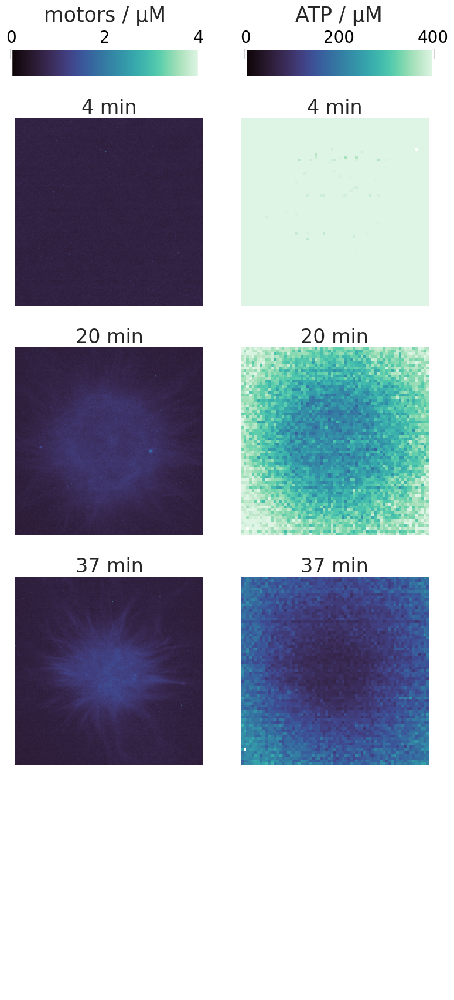

In [16]:
motcrosslinkToIndiv = 2 #motor concentrations are reported in ilid-micro dimers. To represent individual motor concentrations multiply by 2
motmin = 0*motcrosslinkToIndiv
motmax = 2*motcrosslinkToIndiv
atpmin = 0
atpmax = 400 #150

fig, ax = plt.subplots(4,2, figsize=(8,16))

ax[0,0].imshow(motpcmovieims[12], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
ax[1,0].imshow(motpcmovieims[62], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
ax[2,0].imshow(motpcmovieims[112], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
#ax[3,0].imshow(motpcmovieims[162], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')

ax[0,1].imshow(ds_sptm_ATP[12], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
ax[1,1].imshow(ds_sptm_ATP[62], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
ax[2,1].imshow(ds_sptm_ATP[112], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
#ax[3,1].imshow(ds_sptm_ATP[162], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')

#ax.text(10, winsize_um+2, str(round(times_min, 2)), color = 'k')
#ax.text(60, winsize_um+2, " min", color = 'k')
plt.plot([winsize_um-40, winsize_um-10],[-winsize_um+5, -winsize_um+5], c='w')
ax[3,1].text(winsize_um-42, -winsize_um+8, "30 µm", color = 'w', fontsize=13)

ax[0,0].set_title(str(round((times_sec[12] - 20/2)/60)) +' min')
ax[1,0].set_title(str(round((times_sec[62] - 20/2)/60)) +' min')
ax[2,0].set_title(str(round((times_sec[112] - 20/2)/60)) +' min')
#ax[3,0].set_title(str(round((times_sec[162] - 20/2)/60)) +' min')

ax[0,1].set_title(str(round((times_sec[12] - 20/2)/60)) +' min')
ax[1,1].set_title(str(round((times_sec[62] - 20/2)/60)) +' min')
ax[2,1].set_title(str(round((times_sec[112] - 20/2)/60)) +' min')
#ax[3,1].set_title(str(round((times_sec[162] - 20/2)/60)) +' min')

for i in range(4):
    for j in range(2):
        ax[i,j].axis('off')


# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

#### Motor Colorbar ####
caxmot = fig.add_axes([0.05, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarmot = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=motmin, vmax=motmax)),
                    cax=caxmot, 
                    orientation='horizontal')
cbarmot.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarmot.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarmot.ax.xaxis.set_label_position('top')   # Move label to top
cbarmot.set_label('motors / µM', fontsize=25, labelpad=10)


#### ATP Colorbar ####
caxATP = fig.add_axes([0.55, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarATP = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=atpmin, vmax=atpmax)),
                    cax=caxATP, 
                    orientation='horizontal')
cbarATP.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarATP.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarATP.ax.xaxis.set_label_position('top')   # Move label to top
cbarATP.set_label('ATP / µM', fontsize=25, labelpad=10)


        
plt.tight_layout()

#plt.savefig('20250629_sampletMotandATPIms_12-11-2023_r1_Pos2.pdf', bbox_inches='tight')


/home/aduarte/am_atp/analysis/aster/ipykernel_40393/1311111504.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


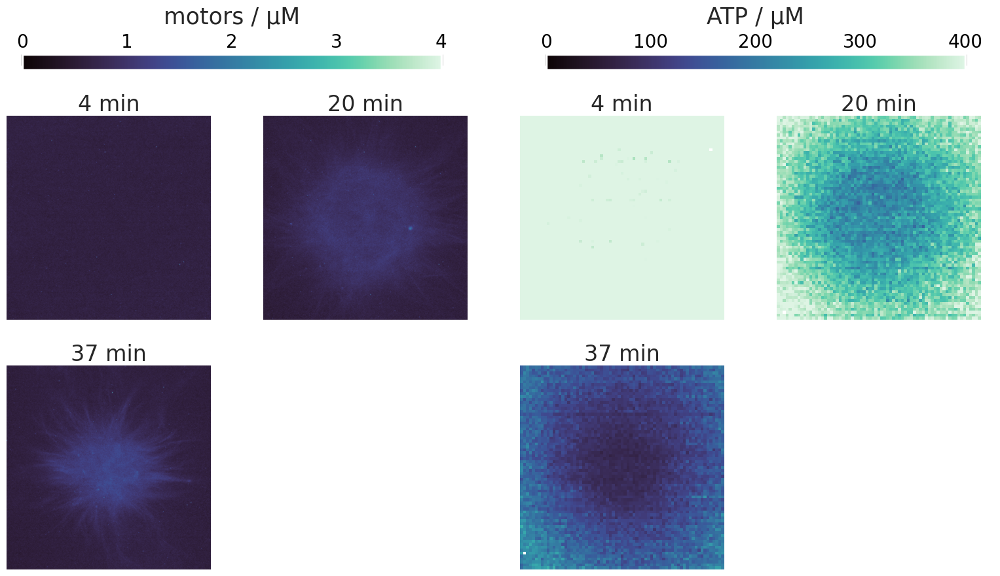

In [18]:
motcrosslinkToIndiv = 2 #motor concentrations are reported in ilid-micro dimers. To represent individual motor concentrations multiply by 2
motmin = 0*motcrosslinkToIndiv
motmax = 2*motcrosslinkToIndiv
atpmin = 0
atpmax = 400 #150

fig, ax = plt.subplots(2,4, figsize=(16,8))
    
ax[0,0].imshow(motpcmovieims[12], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
ax[0,1].imshow(motpcmovieims[62], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
ax[1,0].imshow(motpcmovieims[112], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
#ax[1,1].imshow(motpcmovieims[162], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')

ax[0,2].imshow(ds_sptm_ATP[12], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
ax[0,3].imshow(ds_sptm_ATP[62], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
ax[1,2].imshow(ds_sptm_ATP[112], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
#ax[1,3].imshow(ds_sptm_ATP[162], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')

#ax.text(10, winsize_um+2, str(round(times_min, 2)), color = 'k')
#ax.text(60, winsize_um+2, " min", color = 'k')
plt.plot([winsize_um-40, winsize_um-10],[-winsize_um+5, -winsize_um+5], c='w')
ax[1,3].text(winsize_um-42, -winsize_um+8, "30 µm", color = 'w', fontsize=13)

ax[0,0].set_title(str(round((times_sec[12] - 20/2)/60)) +' min')
ax[0,1].set_title(str(round((times_sec[62] - 20/2)/60)) +' min')
ax[1,0].set_title(str(round((times_sec[112] - 20/2)/60)) +' min')
#ax[1,1].set_title(str(round((times_sec[162] - 20/2)/60)) +' min')

ax[0,2].set_title(str(round((times_sec[12] - 20/2)/60)) +' min')
ax[0,3].set_title(str(round((times_sec[62] - 20/2)/60)) +' min')
ax[1,2].set_title(str(round((times_sec[112] - 20/2)/60)) +' min')
#ax[1,3].set_title(str(round((times_sec[162] - 20/2)/60)) +' min')

for i in range(2):
    for j in range(4):
        ax[i,j].axis('off')


# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

#### Motor Colorbar ####
caxmot = fig.add_axes([0.05, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarmot = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=motmin, vmax=motmax)),
                    cax=caxmot, 
                    orientation='horizontal')
cbarmot.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarmot.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarmot.ax.xaxis.set_label_position('top')   # Move label to top
cbarmot.set_label('motors / µM', fontsize=25, labelpad=10)


#### ATP Colorbar ####
caxATP = fig.add_axes([0.55, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarATP = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=atpmin, vmax=atpmax)),
                    cax=caxATP, 
                    orientation='horizontal')
cbarATP.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarATP.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarATP.ax.xaxis.set_label_position('top')   # Move label to top
cbarATP.set_label('ATP / µM', fontsize=25, labelpad=10)


        
plt.tight_layout()

radial traces

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/776792224.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


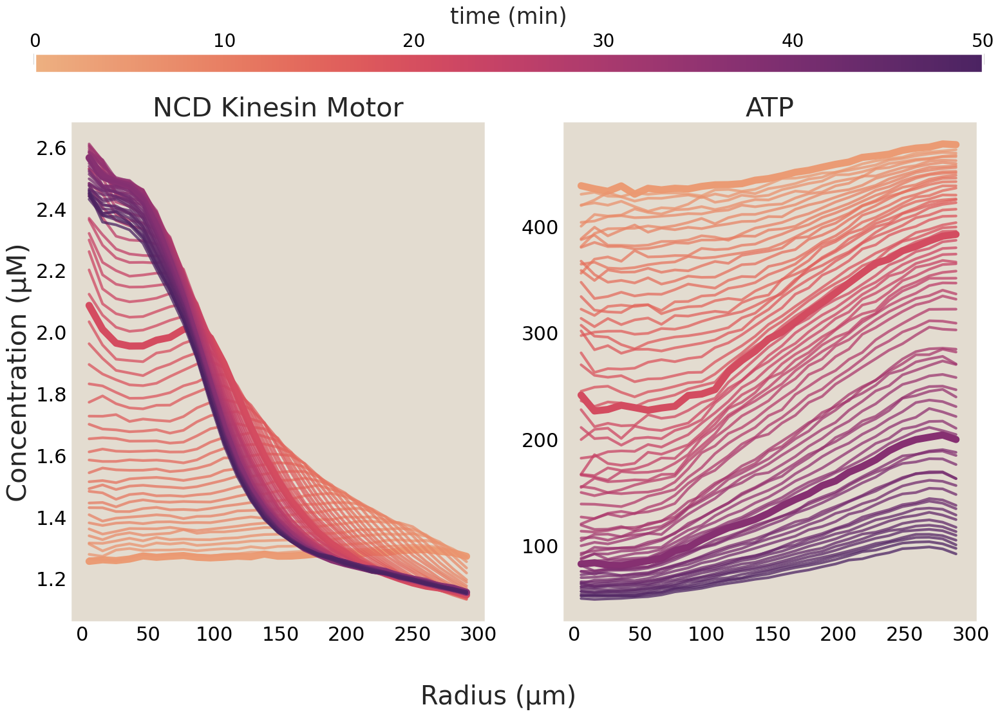

In [19]:
global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=min([h5dic_pc['timesMot'].min(), h5dic_pc['timesATP'].min()]), vmax=max([h5dic_pc['timesMot'].max(), h5dic_pc['timesATP'].max()]))(time))

fig, ax = plt.subplots(1, 2, figsize=(16,10))
for t, time in enumerate(h5dic_pc['timesMot'][12::2]):
    if np.isin(t*2+12, [12, 62, 112, 162]):
        ax[0].plot(h5dic_pc['all_rMotbins'][t*2+12], # report in individual motor rather than crosslinked pairs
                 h5dic_pc['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                 alpha=1,
                 lw=8,
                 color=global_time(time))
    else:
        ax[0].plot(h5dic_pc['all_rMotbins'][t*2+12],
                 h5dic_pc['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                 alpha=0.75,
                 color=global_time(time))


for t, time in enumerate(h5dic_pc['timesATP'][12::2]):
    if np.isin(t*2+12, [12, 62, 112, 162]):
        ax[1].plot(h5dic_pc['all_rATPbins'][t*2+12]*6, #since downsampled by 6
                               h5dic_pc['all_rATPavgs'][t*2+12], 
                               alpha=1, 
                               lw=8,
                               color=global_time(time))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
    else:
        ax[1].plot(h5dic_pc['all_rATPbins'][t*2+12]*6, #since downsampled by 6
                               h5dic_pc['all_rATPavgs'][t*2+12], 
                               alpha=0.75, 
                               color=global_time(time))

ax[0].set_ylabel('Concentration (µM)', fontsize=30)
fig.supxlabel('Radius (µm)')
ax[1].set_xlim(ax[0].set_xlim())

ax[0].set_title('NCD Kinesin Motor', fontsize=30)
ax[1].set_title('ATP', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(h5dic_pc['timesMot'])/60, 
                                                                 vmax=max(h5dic_pc['timesMot'])/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()

#plt.savefig(h5spath_pc+'20250629_MotorATPTraces_postBleachCvat_12-11-2023_r1_Pos2.pdf', bbox_inches='tight', transparent=True)
#plt.savefig('20250629_MotorATPTraces_postBleachCvat_12-11-2023_r1_Pos2.pdf', bbox_inches='tight')


Power

(0.0, 10.0)

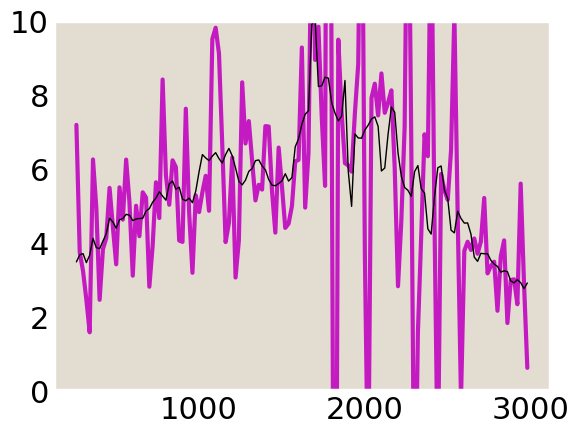

In [20]:
totalPowers_pc=np.sum(h5dic_pc['powerShells'], axis=1)
smoothwindow=5
times_power_pc=h5dic_pc['timesPower']
plt.plot(times_power_pc[12:], totalPowers_pc[12:]/1e8, '-', ms=8, color='m', label='power', lw=3, alpha=0.88)
totalPowers_pc=float_avg(totalPowers_pc, smoothwindow)
plt.plot(times_sec[13:-1], totalPowers_pc[12:]/1e8, color='k', lw=1)
plt.ylim(0, 10)

## select gnames

In [21]:
selectGnames=[gnameList[i] for i in [29, 28, 23]]

In [22]:
selectGnames

['../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif',
 '../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos1.ome.tif',
 '../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif']

In [23]:
# For the a select list of gnames
select_h5dic = []
select_motmovieims =[]
select_ds_sptm_ATP = []
select_times_sec = []
#for g, gname in enumerate(tqdm(selectGnames)): # gs's delbruck lacks tqdm right noww
for g, gname in enumerate(selectGnames):
    h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)
    select_h5dic.append(h5dic)
    
    # read into arrays
    ATP_conc_ims = makeImFromValsList(h5dic['ATP'], h5dic['mask_coords'], h5dic['imshape'])
    mot_conc_ims = makeImFromValsList(h5dic['mot'], h5dic['mask_coords'], h5dic['imshape'])
    mango_mask = makeImFromValsList(np.ones((len(h5dic['mot']), len(h5dic['mask_coords'][0]))), h5dic['mask_coords'], h5dic['imshape'])[0].astype('int')
    
    #find center information and crop accordingly
    centers, axesLengths = cvatCentandRad(gname, annotPath, ATP_conc_ims[0].shape)
    min_dist = min_radius(mango_mask, centers)
    side_length = int(min_dist/np.sqrt(2))
    
    um_per_pixel=0.59
    winsize_um = side_length*um_per_pixel
    extent = [-winsize_um, winsize_um, -winsize_um, winsize_um]
    
    ATPmovieims = []
    motmovieims = []
    
    for i in range(len(ATP_conc_ims)):
        inscribe_crop = np.s_[round(centers[i,1])-side_length:round(centers[i, 1])+side_length,
                         round(centers[i,0])-side_length:round(centers[i,0])+side_length]
        ATPmovieims.append(ATP_conc_ims[i][inscribe_crop])
        motmovieims.append(mot_conc_ims[i][inscribe_crop])
    
    ATPmovieims=np.array(ATPmovieims)
    motmovieims=np.array(motmovieims)
    select_motmovieims.append(motmovieims)
    
    #downsample ATP
    timesATP, ds_sptm_ATP = perform_downsamp(ATPmovieims, timewin=2, pixelwin=6)
    select_ds_sptm_ATP.append(ds_sptm_ATP)
    
    #define the time  of each frame
    times_sec = np.arange(len(motmovieims))*20 #exp_params['interval']
    select_times_sec.append(times_sec)
    times_min = times_sec/60

18
18
18


In [24]:
h5dic['timesATP'][12::2]

array([ 250.,  290.,  330.,  370.,  410.,  450.,  490.,  530.,  570.,
        610.,  650.,  690.,  730.,  770.,  810.,  850.,  890.,  930.,
        970., 1010., 1050., 1090., 1130., 1170., 1210., 1250., 1290.,
       1330., 1370., 1410., 1450., 1490., 1530., 1570., 1610., 1650.,
       1690., 1730., 1770., 1810., 1850., 1890., 1930., 1970., 2010.,
       2050., 2090., 2130., 2170., 2210., 2250., 2290., 2330., 2370.,
       2410., 2450., 2490., 2530., 2570., 2610., 2650., 2690., 2730.,
       2770., 2810., 2850., 2890., 2930., 2970.])

['../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos0.ome.tif',
 '../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos1.ome.tif',
 '../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif',
 '../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2_MMStack_Pos0.ome.tif',
 '../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2_MMStack_Pos1.ome.tif',
 '../

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/2870099932.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


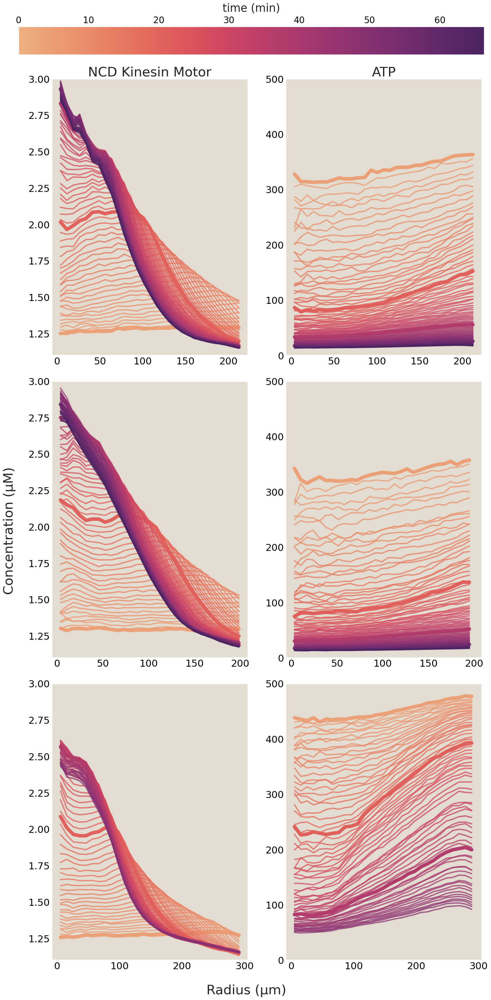

In [25]:
global_timemin = min([select_times_sec[i].min() for i in range(len(select_times_sec))])
global_timemax = max([select_times_sec[i].max() for i in range(len(select_times_sec))])
global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=global_timemin, vmax=global_timemax)(time))

fig, ax = plt.subplots(len(selectGnames), 2, figsize=(16,10*len(selectGnames)))
for idx in range(len(selectGnames)):
    for t, time in enumerate(select_h5dic[idx]['timesMot'][12::2]):
        if np.isin(t*2+12, [12, 62, 112, 162]):
            ax[idx, 0].plot(select_h5dic[idx]['all_rMotbins'][t*2+12], # report in individual motor rather than crosslinked pairs
                     select_h5dic[idx]['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                     alpha=1,
                     lw=8,
                     color=global_time(time))
        else:
            ax[idx, 0].plot(select_h5dic[idx]['all_rMotbins'][t*2+12],
                     select_h5dic[idx]['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                     alpha=0.75,
                     color=global_time(time))
    
    
    for t, time in enumerate(select_h5dic[idx]['timesATP'][12::2]):
        if np.isin(t*2+12, [12, 62, 112, 162]):
            ax[idx,1].plot(select_h5dic[idx]['all_rATPbins'][t*2+12]*6, #since downsampled by 6
                                   select_h5dic[idx]['all_rATPavgs'][t*2+12], 
                                   alpha=1, 
                                   lw=8,
                                   color=global_time(time))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        else:
            ax[idx, 1].plot(select_h5dic[idx]['all_rATPbins'][t*2+12]*6, #since downsampled by 6
                                   select_h5dic[idx]['all_rATPavgs'][t*2+12], 
                                   alpha=0.75, 
                                   color=global_time(time))
    ax[idx,1].set_xlim(ax[idx,0].set_xlim())
    ax[idx,1].set_ylim(0, 500)
    ax[idx,0].set_ylim(1.1, 3)

fig.supylabel('Concentration (µM)', fontsize=30)
fig.supxlabel('Radius (µm)', fontsize=30)


ax[0,0].set_title('NCD Kinesin Motor', fontsize=30)
ax[0,1].set_title('ATP', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=global_timemin/60, 
                                                                 vmax=global_timemax/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()


#plt.savefig('20260510_selectExamples_motandatp.pdf', bbox_inches='tight')


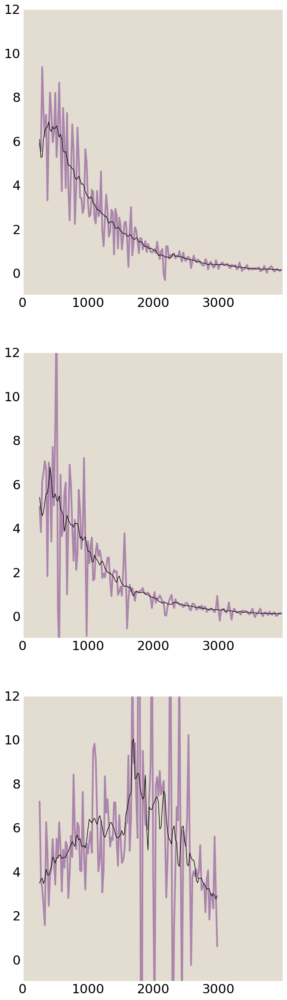

In [26]:
fig, ax = plt.subplots(len(selectGnames), figsize=(8,10*len(selectGnames)))
for idx in range(len(selectGnames)):
    totalPowers=np.sum(select_h5dic[idx]['powerShells'], axis=1)
    times_power=select_h5dic[idx]['timesPower']
    ax[idx].plot(times_power[12:], totalPowers[12:]/1e8, '-', ms=8, color='#AB85AC', label='power', lw=3, alpha=1)
    smoothwindow=5
    totalPowers=float_avg(totalPowers, smoothwindow)
    ax[idx].plot(select_times_sec[idx][13:-1], totalPowers[12:]/1e8, color='k', lw=1)
    ax[idx].set_ylim(-1, 12)
    ax[idx].set_xlim(global_timemin, global_timemax+10)

#plt.savefig('20260510_selectExamples_power.pdf', bbox_inches='tight')

In [27]:
select_motmovieims[0][0]

array([[0.54136229, 0.58610958, 0.63725311, ..., 0.56328368, 0.6006003 ,
        0.6503939 ],
       [0.6435644 , 0.66924036, 0.5929212 , ..., 0.56989133, 0.638529  ,
        0.63827753],
       [0.61198795, 0.65679723, 0.64422411, ..., 0.58277267, 0.60760015,
        0.57605374],
       ...,
       [0.50900018, 0.49547878, 0.54390752, ..., 0.57620406, 0.61160827,
        0.62566251],
       [0.60531288, 0.49549162, 0.64031315, ..., 0.56209147, 0.65441245,
        0.6542359 ],
       [0.59156978, 0.55055964, 0.59213227, ..., 0.5835548 , 0.66165996,
        0.59035468]], shape=(306, 306))

In [28]:
select_times_sec

[array([   0,   20,   40,   60,   80,  100,  120,  140,  160,  180,  200,
         220,  240,  260,  280,  300,  320,  340,  360,  380,  400,  420,
         440,  460,  480,  500,  520,  540,  560,  580,  600,  620,  640,
         660,  680,  700,  720,  740,  760,  780,  800,  820,  840,  860,
         880,  900,  920,  940,  960,  980, 1000, 1020, 1040, 1060, 1080,
        1100, 1120, 1140, 1160, 1180, 1200, 1220, 1240, 1260, 1280, 1300,
        1320, 1340, 1360, 1380, 1400, 1420, 1440, 1460, 1480, 1500, 1520,
        1540, 1560, 1580, 1600, 1620, 1640, 1660, 1680, 1700, 1720, 1740,
        1760, 1780, 1800, 1820, 1840, 1860, 1880, 1900, 1920, 1940, 1960,
        1980, 2000, 2020, 2040, 2060, 2080, 2100, 2120, 2140, 2160, 2180,
        2200, 2220, 2240, 2260, 2280, 2300, 2320, 2340, 2360, 2380, 2400,
        2420, 2440, 2460, 2480, 2500, 2520, 2540, 2560, 2580, 2600, 2620,
        2640, 2660, 2680, 2700, 2720, 2740, 2760, 2780, 2800, 2820, 2840,
        2860, 2880, 2900, 2920, 2940, 

In [29]:
selectGnames[0]

'../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif'

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/811322941.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


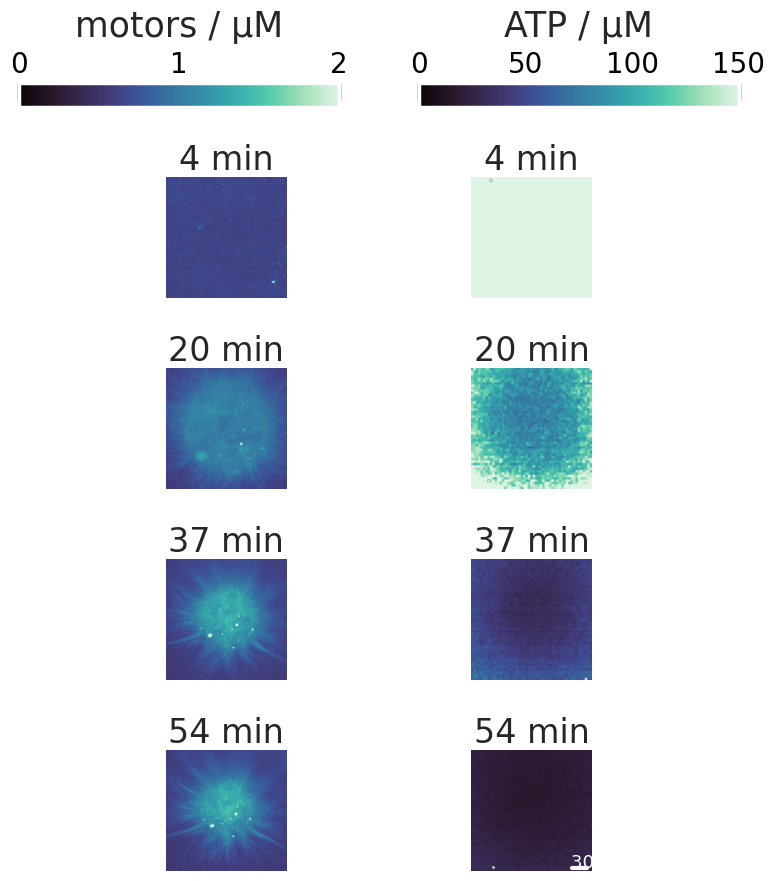

In [30]:
motcrosslinkToIndiv = 2 #motor concentrations are reported in ilid-micro dimers. To represent individual motor concentrations multiply by 2
motmin = 0*motcrosslinkToIndiv
motmax = 1*motcrosslinkToIndiv
atpmin = 0
atpmax = 150 #150
i=0
fig, ax = plt.subplots(4,2, figsize=(8,8))

ax[0,0].imshow(select_motmovieims[i][12], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
ax[1,0].imshow(select_motmovieims[i][62], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
ax[2,0].imshow(select_motmovieims[i][112], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
if 162<len(select_motmovieims[i]):
    ax[3,0].imshow(select_motmovieims[i][162], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')

ax[0,1].imshow(select_ds_sptm_ATP[i][12], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
ax[1,1].imshow(select_ds_sptm_ATP[i][62], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
ax[2,1].imshow(select_ds_sptm_ATP[i][112], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
if 162<len(select_ds_sptm_ATP[i]):
    ax[3,1].imshow(select_ds_sptm_ATP[i][162], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')

#ax.text(10, winsize_um+2, str(round(times_min, 2)), color = 'k')
#ax.text(60, winsize_um+2, " min", color = 'k')
plt.plot([winsize_um-40, winsize_um-10],[-winsize_um+5, -winsize_um+5], c='w')
ax[3,1].text(winsize_um-42, -winsize_um+8, "30 µm", color = 'w', fontsize=13)

ax[0,0].set_title(str(round((select_times_sec[i][12] - 20/2)/60)) +' min')
ax[1,0].set_title(str(round((select_times_sec[i][62] - 20/2)/60)) +' min')
ax[2,0].set_title(str(round((select_times_sec[i][112] - 20/2)/60)) +' min')
if 162<len(select_ds_sptm_ATP[i]):
    ax[3,0].set_title(str(round((select_times_sec[i][162] - 20/2)/60)) +' min')

ax[0,1].set_title(str(round((select_times_sec[i][12] - 20/2)/60)) +' min')
ax[1,1].set_title(str(round((select_times_sec[i][62] - 20/2)/60)) +' min')
ax[2,1].set_title(str(round((select_times_sec[i][112] - 20/2)/60)) +' min')
if 162<len(select_ds_sptm_ATP[i]):
    ax[3,1].set_title(str(round((select_times_sec[i][162] - 20/2)/60)) +' min')

for i in range(4):
    for j in range(2):
        ax[i,j].axis('off')


# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

#### Motor Colorbar ####
caxmot = fig.add_axes([0.05, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarmot = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=motmin, vmax=motmax)),
                    cax=caxmot, 
                    orientation='horizontal')
cbarmot.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarmot.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarmot.ax.xaxis.set_label_position('top')   # Move label to top
cbarmot.set_label('motors / µM', fontsize=25, labelpad=10)


#### ATP Colorbar ####
caxATP = fig.add_axes([0.55, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarATP = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=atpmin, vmax=atpmax)),
                    cax=caxATP, 
                    orientation='horizontal')
cbarATP.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarATP.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarATP.ax.xaxis.set_label_position('top')   # Move label to top
cbarATP.set_label('ATP / µM', fontsize=25, labelpad=10)


        
plt.tight_layout()

#plt.savefig('20260511_selectATPandMotIms_12-11-2023_r1_Pos2.pdf', bbox_inches='tight')


/home/aduarte/am_atp/analysis/aster/ipykernel_40393/1399196477.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


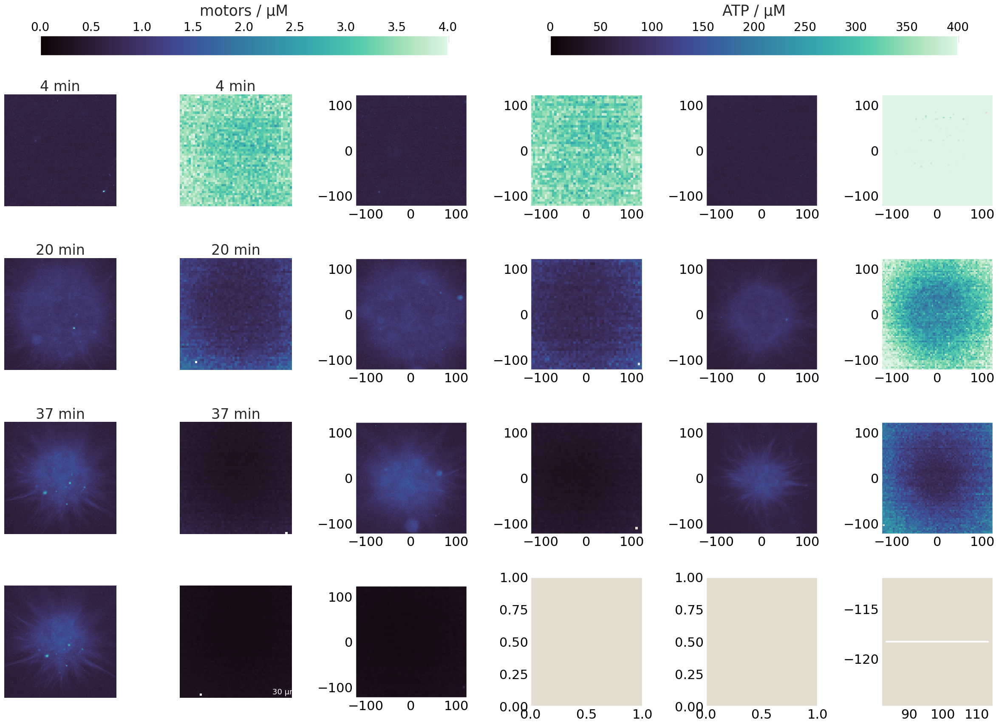

In [31]:
motcrosslinkToIndiv = 2 #motor concentrations are reported in ilid-micro dimers. To represent individual motor concentrations multiply by 2
motmin = 0*motcrosslinkToIndiv
motmax = 2*motcrosslinkToIndiv
atpmin = 0
atpmax = 400 #150

fig, ax = plt.subplots(4,6, figsize=(24,16))
for i in range(len(selectGnames)):
    ax[0,2*i].imshow(select_motmovieims[i][12], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
    ax[1,2*i].imshow(select_motmovieims[i][62], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
    ax[2,2*i].imshow(select_motmovieims[i][112], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')
    if 162<len(select_motmovieims[i]):
        ax[3,2*i].imshow(select_motmovieims[i][162], vmin=motmin, vmax=motmax, extent=extent, cmap='mako')

    ax[0,1+2*i].imshow(select_ds_sptm_ATP[i][12], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
    ax[1,1+2*i].imshow(select_ds_sptm_ATP[i][62], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
    ax[2,1+2*i].imshow(select_ds_sptm_ATP[i][112], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')
    if 162<len(select_ds_sptm_ATP[i]):
        ax[3,1+i].imshow(select_ds_sptm_ATP[i][162], vmin=atpmin, vmax=atpmax, extent=extent, cmap='mako')

#ax.text(10, winsize_um+2, str(round(times_min, 2)), color = 'k')
#ax.text(60, winsize_um+2, " min", color = 'k')
plt.plot([winsize_um-40, winsize_um-10],[-winsize_um+5, -winsize_um+5], c='w')
ax[3,1].text(winsize_um-42, -winsize_um+8, "30 µm", color = 'w', fontsize=13)

ax[0,0].set_title(str(round((times_sec[12] - 20/2)/60)) +' min')
ax[1,0].set_title(str(round((times_sec[62] - 20/2)/60)) +' min')
ax[2,0].set_title(str(round((times_sec[112] - 20/2)/60)) +' min')
#ax[3,0].set_title(str(round((times_sec[162] - 20/2)/60)) +' min')

ax[0,1].set_title(str(round((times_sec[12] - 20/2)/60)) +' min')
ax[1,1].set_title(str(round((times_sec[62] - 20/2)/60)) +' min')
ax[2,1].set_title(str(round((times_sec[112] - 20/2)/60)) +' min')
#ax[3,1].set_title(str(round((times_sec[162] - 20/2)/60)) +' min')

for i in range(4):
    for j in range(2):
        ax[i,j].axis('off')


# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

#### Motor Colorbar ####
caxmot = fig.add_axes([0.05, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarmot = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=motmin, vmax=motmax)),
                    cax=caxmot, 
                    orientation='horizontal')
cbarmot.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarmot.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarmot.ax.xaxis.set_label_position('top')   # Move label to top
cbarmot.set_label('motors / µM', fontsize=25, labelpad=10)


#### ATP Colorbar ####
caxATP = fig.add_axes([0.55, 1, 0.4, 0.03])  # horizontal [left, bottom, width, height]
cbarATP = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("mako", as_cmap=True), 
                                             norm=mcolors.Normalize(vmin=atpmin, vmax=atpmax)),
                    cax=caxATP, 
                    orientation='horizontal')
cbarATP.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbarATP.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbarATP.ax.xaxis.set_label_position('top')   # Move label to top
cbarATP.set_label('ATP / µM', fontsize=25, labelpad=10)


        
plt.tight_layout()

#plt.savefig('20250629_sampletMotandATPIms_12-11-2023_r1_Pos2.pdf', bbox_inches='tight')


## small multiple plots

In [32]:
#find all the files that have 0.6 in the name
pt6Mot = np.array([i for i in range(len(gnameList)) if '0.6' in gnameList[i]])
#sort the files by date and repeat number
pt6Mot=pt6Mot[np.argsort([gnameList[i] for i in pt6Mot])]
# pull the files in order as a subset
selectGnames = [gnameList[i] for i in pt6Mot]

In [33]:
# For the a select list of gnames
select_h5dic = []
select_motmovieims =[]
select_ds_sptm_ATP = []
select_times_sec = []
# for g, gname in enumerate(tqdm(selectGnames)):
for g, gname in enumerate(selectGnames):
    h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)
    select_h5dic.append(h5dic)
    
    # read into arrays
    ATP_conc_ims = makeImFromValsList(h5dic['ATP'], h5dic['mask_coords'], h5dic['imshape'])
    mot_conc_ims = makeImFromValsList(h5dic['mot'], h5dic['mask_coords'], h5dic['imshape'])
    mango_mask = makeImFromValsList(np.ones((len(h5dic['mot']), len(h5dic['mask_coords'][0]))), h5dic['mask_coords'], h5dic['imshape'])[0].astype('int')
    
    #find center information and crop accordingly
    centers, axesLengths = cvatCentandRad(gname, annotPath, ATP_conc_ims[0].shape)
    min_dist = min_radius(mango_mask, centers)
    side_length = int(min_dist/np.sqrt(2))
    
    um_per_pixel=0.59
    winsize_um = side_length*um_per_pixel
    extent = [-winsize_um, winsize_um, -winsize_um, winsize_um]
    
    ATPmovieims = []
    motmovieims = []
    
    for i in range(len(ATP_conc_ims)):
        inscribe_crop = np.s_[round(centers[i,1])-side_length:round(centers[i, 1])+side_length,
                         round(centers[i,0])-side_length:round(centers[i,0])+side_length]
        ATPmovieims.append(ATP_conc_ims[i][inscribe_crop])
        motmovieims.append(mot_conc_ims[i][inscribe_crop])
    
    ATPmovieims=np.array(ATPmovieims)
    motmovieims=np.array(motmovieims)
    select_motmovieims.append(motmovieims)
    
    #downsample ATP
    timesATP, ds_sptm_ATP = perform_downsamp(ATPmovieims, timewin=2, pixelwin=6)
    select_ds_sptm_ATP.append(ds_sptm_ATP)
    
    #define the time  of each frame
    times_sec = np.arange(len(motmovieims))*20 #exp_params['interval']
    select_times_sec.append(times_sec)
    times_min = times_sec/60

18
18
18
18
18
18
18
18
18
18
18
18
18
18
18


In [34]:
for idx in range(len(selectGnames)):
    print(idx//3,idx%3)

0 0
0 1
0 2
1 0
1 1
1 2
2 0
2 1
2 2
3 0
3 1
3 2
4 0
4 1
4 2


In [116]:
select_h5dic[idx]['all_rMotbins'][0], select_h5dic[idx]['all_rATPbins'][0]*6

(array([  3.98275862,  11.94827586,  19.9137931 ,  27.87931034,
         35.84482759,  43.81034483,  51.77586207,  59.74137931,
         67.70689655,  75.67241379,  83.63793103,  91.60344828,
         99.56896552, 107.53448276, 115.5       , 123.46551724,
        131.43103448, 139.39655172, 147.36206897, 155.32758621,
        163.29310345, 171.25862069, 179.22413793, 187.18965517,
        195.15517241, 203.12068966, 211.0862069 , 219.05172414,
        227.01724138]),
 array([  3.93103448,  11.79310345,  19.65517241,  27.51724138,
         35.37931034,  43.24137931,  51.10344828,  58.96551724,
         66.82758621,  74.68965517,  82.55172414,  90.4137931 ,
         98.27586207, 106.13793103, 114.        , 121.86206897,
        129.72413793, 137.5862069 , 145.44827586, 153.31034483,
        161.17241379, 169.03448276, 176.89655172, 184.75862069,
        192.62068966, 200.48275862, 208.34482759, 216.20689655,
        224.06896552]))

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14


/home/aduarte/am_atp/analysis/aster/ipykernel_40393/3544925282.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


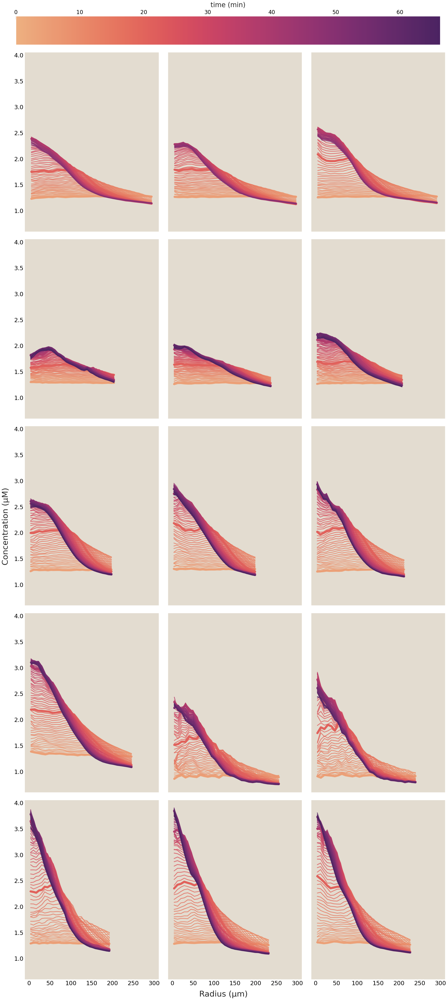

In [35]:
global_timemin = min([select_times_sec[i].min() for i in range(len(select_times_sec))])
global_timemax = max([select_times_sec[i].max() for i in range(len(select_times_sec))])
global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=global_timemin, vmax=global_timemax)(time))

fig, ax = plt.subplots(len(selectGnames)//3, 3, figsize=(24,10*len(selectGnames)/3), sharex=True, sharey=True)
for idx in range(len(selectGnames)):
    print(idx)
    for t, time in enumerate(select_h5dic[idx]['timesMot'][12::2]):
        if np.isin(t*2+12, [12, 62, 112, 162]):
            ax[idx//3,idx%3].plot(select_h5dic[idx]['all_rMotbins'][t*2+12], # report in individual motor rather than crosslinked pairs
                     select_h5dic[idx]['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                     alpha=1,
                     lw=8,
                     color=global_time(time))
        else:
            ax[idx//3,idx%3].plot(select_h5dic[idx]['all_rMotbins'][t*2+12],
                     select_h5dic[idx]['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                     alpha=0.75,
                     color=global_time(time))
            

fig.supylabel('Concentration (µM)', fontsize=30)
fig.supxlabel('Radius (µm)', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=global_timemin/60, 
                                                                 vmax=global_timemax/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()


#plt.savefig('20260511_smMult_selectMotors.pdf', bbox_inches='tight')


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14


/home/aduarte/am_atp/analysis/aster/ipykernel_40393/3347467846.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


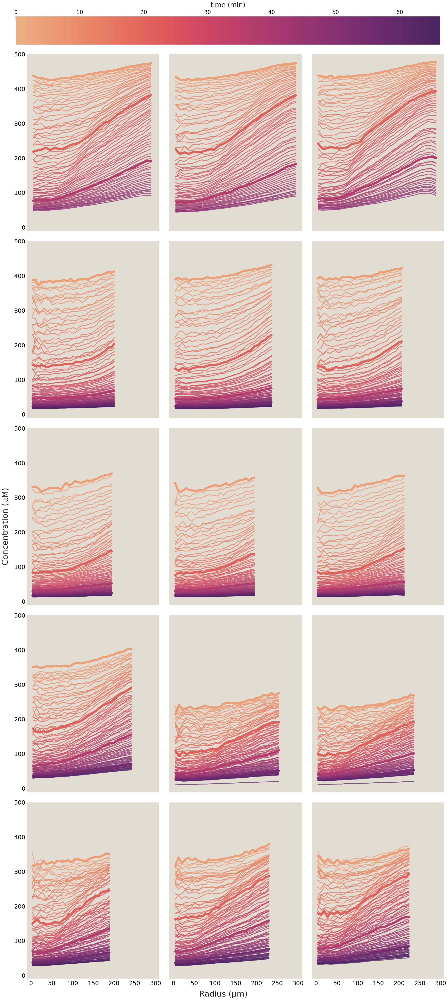

In [36]:
global_timemin = min([select_times_sec[i].min() for i in range(len(select_times_sec))])
global_timemax = max([select_times_sec[i].max() for i in range(len(select_times_sec))])
global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=global_timemin, vmax=global_timemax)(time))

fig, ax = plt.subplots(len(selectGnames)//3, 3, figsize=(24,10*len(selectGnames)/3), sharex=True, sharey=True)
for idx in range(len(selectGnames)):
    print(idx)
    for t, time in enumerate(select_h5dic[idx]['timesATP'][12::2]):
        if np.isin(t*2+12, [12, 62, 112, 162]):
            ax[idx//3,idx%3].plot(select_h5dic[idx]['all_rATPbins'][t*2+12]*6, #since downsampled by 6
                                   select_h5dic[idx]['all_rATPavgs'][t*2+12], 
                                   alpha=1, 
                                   lw=8,
                                   color=global_time(time))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        else:
            ax[idx//3,idx%3].plot(select_h5dic[idx]['all_rATPbins'][t*2+12]*6, #since downsampled by 6
                                   select_h5dic[idx]['all_rATPavgs'][t*2+12], 
                                   alpha=0.75, 
                                   color=global_time(time))
            

fig.supylabel('Concentration (µM)', fontsize=30)
fig.supxlabel('Radius (µm)', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=global_timemin/60, 
                                                                 vmax=global_timemax/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()


#plt.savefig('20260511_smMult_selectATP.pdf', bbox_inches='tight')

### Reproducibility of spatial gradients 

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14


/home/aduarte/am_atp/analysis/aster/ipykernel_40393/564368354.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


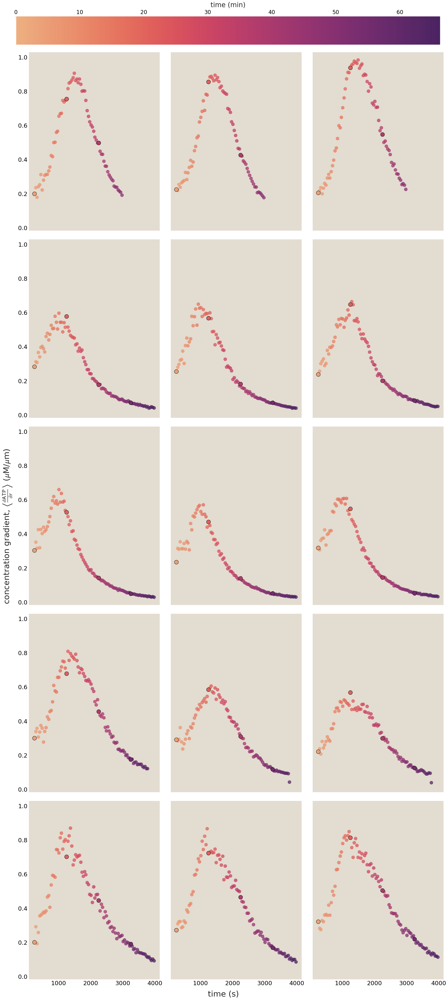

In [37]:
### extract gradient information

global_timemin = min([select_times_sec[i].min() for i in range(len(select_times_sec))])
global_timemax = max([select_times_sec[i].max() for i in range(len(select_times_sec))])
global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=global_timemin, vmax=global_timemax)(time))

fig, ax = plt.subplots(len(selectGnames)//3, 3, figsize=(24,10*len(selectGnames)/3), sharex=True, sharey=True)
for idx in range(len(selectGnames)):
    print(idx)
    for t, time in enumerate(select_h5dic[idx]['timesATP'][12::2]): # all times, not just subsampled
        ## find the ATP value measured closest to that at 100µm 
        rPosVals=select_h5dic[idx]['all_rATPbins'][t*2+12]*6
        atpValsOverR=select_h5dic[idx]['all_rATPavgs'][t*2+12]

        startLocInUm=100; #µm
        endLocInUm=200;   #µm


        idxClosestToStart=np.where((abs(rPosVals-startLocInUm))==min(abs(rPosVals-startLocInUm)))[0][0]
        idxClosestToEnd=np.where((abs(rPosVals-endLocInUm))==min(abs(rPosVals-endLocInUm)))[0][0]
        avg_spatialGradientAtThisTime=(atpValsOverR[idxClosestToEnd]-atpValsOverR[idxClosestToStart])/(rPosVals[idxClosestToEnd]-rPosVals[idxClosestToStart])


        if np.isin(t*2+12, [12, 62, 112, 162]):
            ax[idx//3,idx%3].plot(time, 
                                  avg_spatialGradientAtThisTime,
                                  'o',
                                  alpha=1, 
                                  lw=8,
                                  ms=15,
                                  mec='k',
                                  color=global_time(time),
                                 zorder=np.inf)#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        else:
            ax[idx//3,idx%3].plot(time, 
                                  avg_spatialGradientAtThisTime,
                                  'o',
                                  alpha=0.75, 
                                  color=global_time(time))
            

fig.supylabel(r'concentration gradient, $\left\langle \frac{\partial \mathrm{ATP}}{\partial r}\right\rangle$ ($\mu$M/$\mu$m)', fontsize=30)
fig.supxlabel('time (s)', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=global_timemin/60, 
                                                                 vmax=global_timemax/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()


#plt.savefig('20260512_smMult_avgATPgradientOverTime.pdf', bbox_inches='tight')

### power

$\textcolor{red}{\text{AD EDIT: 20260918:}}$

$\textcolor{red}{\text{changed axis labels from conc to ATP/s and radius to time}}$
$\textcolor{red}{\text{the plots looked correct just the labels were wrong}}$

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/4292503022.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


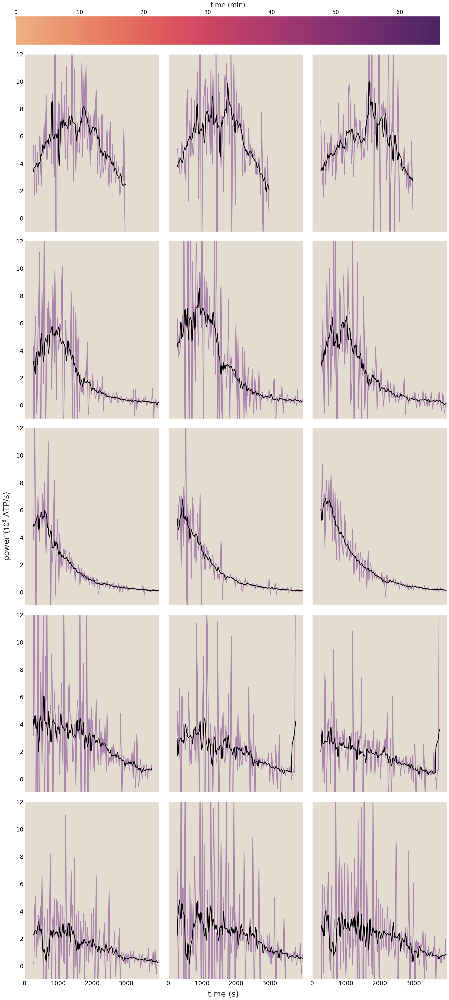

In [39]:
global_timemin = min([select_times_sec[i].min() for i in range(len(select_times_sec))])
global_timemax = max([select_times_sec[i].max() for i in range(len(select_times_sec))])
global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=global_timemin, vmax=global_timemax)(time))

fig, ax = plt.subplots(len(selectGnames)//3, 3, figsize=(24,10*len(selectGnames)/3), sharex=True, sharey=True)
for idx in range(len(selectGnames)):
    totalPowers=np.sum(select_h5dic[idx]['powerShells'], axis=1)
    times_power=select_h5dic[idx]['timesPower']
    ax[idx//3, idx%3].plot(times_power[12:], totalPowers[12:]/1e8, '-', ms=8, color='#AB85AC', label='power', lw=3, alpha=1)
    smoothwindow=5
    totalPowers=float_avg(totalPowers, smoothwindow)
    ax[idx//3, idx%3].plot(select_times_sec[idx][13:-1], totalPowers[12:]/1e8, color='k', lw=3)
    ax[idx//3, idx%3].set_ylim(-1, 12)
    ax[idx//3, idx%3].set_xlim(global_timemin, global_timemax+10)
            

fig.supylabel(rf'power ($10^8$ ATP/s)', fontsize=30)#fig.supylabel('Concentration (µM)', fontsize=30)
fig.supxlabel('time (s)', fontsize=30)#fig.supxlabel('Radius (µm)', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=global_timemin/60, 
                                                                 vmax=global_timemax/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()


#plt.savefig('20260511_smMult_selectPower.pdf', bbox_inches='tight')

# $\textcolor{red}{\text{20260918 - power vs diferent quantities in response to reviewers}}$

In [50]:
select_rad = []
for idx in range(len(selectGnames)):
    select_rad.append(select_h5dic[idx]['all_rATPbins'][0])

global_radmin = min([select_rad[i].min() for i in range(len(select_rad))])
global_radmax = max([select_rad[i].max() for i in range(len(select_rad))])
global_rad=lambda rad:sns.color_palette("cool", as_cmap=True)(matplotlib.colors.Normalize(vmin=global_radmin, vmax=global_radmax)(rad))


In [73]:
select_h5dic[idx]['powerShells']

array([[-4.17866879e+05,  1.10714979e+06, -1.73415696e+06, ...,
        -3.64663914e+07, -5.23270314e+07, -4.64231815e+07],
       [ 8.82509203e+05,  1.58407936e+06,  2.76769976e+06, ...,
        -2.15541027e+06, -5.35373737e+06,  1.49329015e+06],
       [ 1.48035047e+06,  3.04579290e+06,  3.31361118e+06, ...,
         1.24418214e+07,  1.34673983e+07, -2.98800938e+06],
       ...,
       [ 3.56887236e+04,  1.26263679e+06,  1.34523923e+06, ...,
         6.96042523e+07,  7.45475819e+07,  7.91879879e+07],
       [ 3.24388240e+05,  7.68640644e+05,  7.51061623e+05, ...,
         1.64173980e+07,  5.00750921e+06,  1.57776573e+06],
       [ 3.36270528e+05, -3.97546544e+05,  3.71164582e+04, ...,
        -2.68841667e+07, -2.84071020e+07, -3.10459585e+07]],
      shape=(149, 29))

In [58]:
len(select_h5dic[0]['powerShells'][:,r])

149

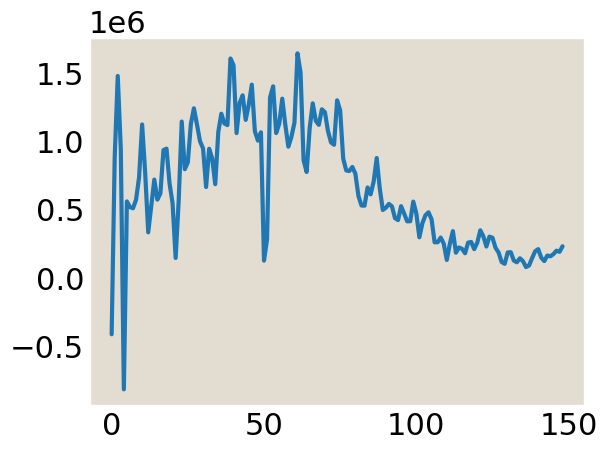

In [56]:
plt.plot(float_avg(select_h5dic[0]['powerShells'][:,r], smoothwindow))

power vs time  --> colorbar radius

In [ ]:
fig, ax = plt.subplots(len(selectGnames)//3, 3, figsize=(24,10*len(selectGnames)/3), sharex=True, sharey=True)
for idx in range(len(selectGnames)):
    for r, rad in enumerate(select_h5dic[idx]['all_rATPbins'][0]): #*6*0.59): #6*umperpixel):
        #totalPowers=np.sum(select_h5dic[idx]['powerShells'], axis=1)
        #times_power=select_h5dic[idx]['timesPower']
        #ax[idx//3, idx%3].plot(times_power[12:], totalPowers[12:]/1e8, '-', ms=8, color='#AB85AC', label='power', lw=3, alpha=1)
        smoothwindow=5
        radPowers=float_avg(select_h5dic[idx]['powerShells'][:,r], smoothwindow)
        ax[idx//3, idx%3].plot(select_rad[idx], radPowers/1e8, color='k', lw=3)
    #ax[idx//3, idx%3].set_ylim(-1, 12)
    ax[idx//3, idx%3].set_xlim(global_radmin, global_radmax*1.1)
    
# #power
# for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
#     ax[2][3].plot(h5dic['timesPower'], 
#                   h5dic['powerShells'][:,r], 
#                   color = radcolorPalette(radnorm(rad)), 
#                   lw=1)
# ax[2][3].set_xlabel('seconds')
# ax[2][3].set_ylabel('ATP/s')

power vs radius --> colorbar time

In [82]:
select_h5dic[idx]['all_rATPbins'][0]

array([ 0.65517241,  1.96551724,  3.27586207,  4.5862069 ,  5.89655172,
        7.20689655,  8.51724138,  9.82758621, 11.13793103, 12.44827586,
       13.75862069, 15.06896552, 16.37931034, 17.68965517, 19.        ,
       20.31034483, 21.62068966, 22.93103448, 24.24137931, 25.55172414,
       26.86206897, 28.17241379, 29.48275862, 30.79310345, 32.10344828,
       33.4137931 , 34.72413793, 36.03448276, 37.34482759])

In [93]:
len(select_h5dic[idx]['powerShells'][t])

29

In [104]:
len(select_h5dic[idx]['timesATP'])

199

In [103]:
len(select_h5dic[idx]['powerShells'])

198

In [140]:
h5dic_pc['all_rATPavgs']*um_per_pixel

array([[275.40339586, 274.79882655, 273.3889116 , ..., 285.78412931,
        285.50989906, 285.61750496],
       [273.72119001, 276.24714786, 274.83632404, ..., 287.50761673,
        287.45562377, 287.66620471],
       [268.05585454, 272.81372548, 271.75169676, ..., 287.28208368,
        287.69887381, 287.49733796],
       ...,
       [ 29.73057009,  29.86661525,  29.64975046, ...,  59.05199942,
         58.10966847,  55.40889771],
       [ 29.47178141,  28.9516863 ,  29.26092939, ...,  58.05021573,
         56.95685812,  54.19063785],
       [ 28.72471869,  28.67142035,  29.17681897, ...,  57.7586579 ,
         56.54712525,  53.36788755]], shape=(150, 29))

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/3743946908.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


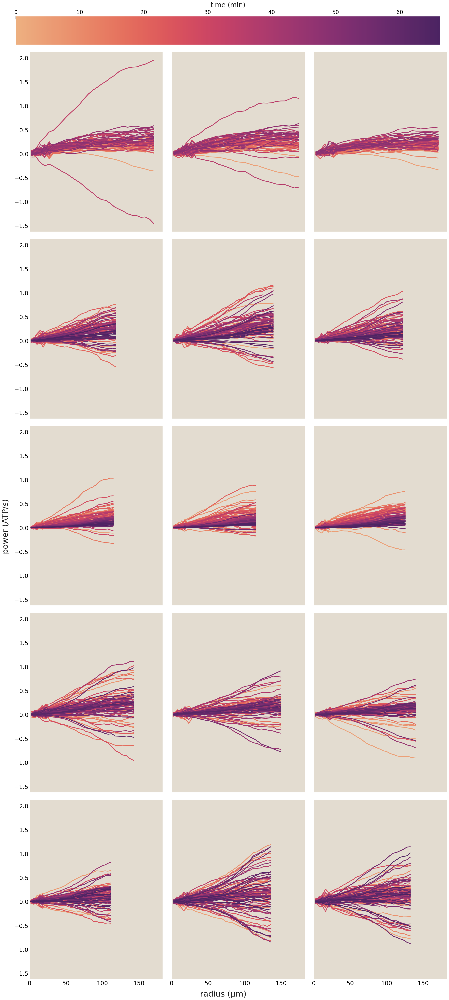

In [107]:
fig, ax = plt.subplots(len(selectGnames)//3, 3, figsize=(24,10*len(selectGnames)/3), sharex=True, sharey=True)
for idx in range(len(selectGnames)):
    #for r, rad in enumerate(select_h5dic[idx]['all_rATPbins'][0]): #*6*0.59): #6*umperpixel):
    for t, time in enumerate(select_h5dic[idx]['timesPower'][12::2]):
        #totalPowers=np.sum(select_h5dic[idx]['powerShells'], axis=1)
        #times_power=select_h5dic[idx]['timesPower']
        #ax[idx//3, idx%3].plot(times_power[12:], totalPowers[12:]/1e8, '-', ms=8, color='#AB85AC', label='power', lw=3, alpha=1)
        smoothwindow=5
        radPowers=float_avg(select_h5dic[idx]['powerShells'][t], smoothwindow)
        ax[idx//3, idx%3].plot(select_rad[idx]*6*um_per_pixel, radPowers/1e8, color=global_time(time), lw=3)
    #ax[idx//3, idx%3].set_ylim(-1, 12)
    ax[idx//3, idx%3].set_xlim(global_radmin*6*um_per_pixel-2, global_radmax*6*um_per_pixel*1.05)

fig.supylabel('power (ATP/s)', fontsize=30)
fig.supxlabel('radius (µm)', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]


cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=global_timemin/60, 
                                                                 vmax=global_timemax/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()

# #power
# for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
#     ax[2][3].plot(h5dic['timesPower'], 
#                   h5dic['powerShells'][:,r], 
#                   color = radcolorPalette(radnorm(rad)), 
#                   lw=1)
# ax[2][3].set_xlabel('seconds')
# ax[2][3].set_ylabel('ATP/s')

In [159]:
2*np.pi*h5dic_pc['all_rATPbins'][0]*1.68965517*70*10**(-18)*1000*36*0.59**2

array([7.86775088e-12, 2.36032527e-11, 3.93387544e-11, 5.50742562e-11,
       7.08097580e-11, 8.65452597e-11, 1.02280761e-10, 1.18016263e-10,
       1.33751765e-10, 1.49487267e-10, 1.65222769e-10, 1.80958270e-10,
       1.96693772e-10, 2.12429274e-10, 2.28164776e-10, 2.43900277e-10,
       2.59635779e-10, 2.75371281e-10, 2.91106783e-10, 3.06842284e-10,
       3.22577786e-10, 3.38313288e-10, 3.54048790e-10, 3.69784292e-10,
       3.85519793e-10, 4.01255295e-10, 4.16990797e-10, 4.32726299e-10,
       4.48461800e-10])

In [160]:
h5dic_pc[]

array([1200, 1920])

In [145]:
h5dic_pc['ATP_shell_vol_L']

array([7.86775089e-12, 2.36032527e-11, 3.93387545e-11, 5.50742563e-11,
       7.08097581e-11, 8.65452598e-11, 1.02280762e-10, 1.18016263e-10,
       1.33751765e-10, 1.49487267e-10, 1.65222769e-10, 1.80958271e-10,
       1.96693772e-10, 2.12429274e-10, 2.28164776e-10, 2.43900278e-10,
       2.59635780e-10, 2.75371281e-10, 2.91106783e-10, 3.06842285e-10,
       3.22577787e-10, 3.38313288e-10, 3.54048790e-10, 3.69784292e-10,
       3.85519794e-10, 4.01255296e-10, 4.16990797e-10, 4.32726299e-10,
       4.48461801e-10])

In [41]:
h5dic.keys()

dict_keys(['ATP_centCrop', 'Mot_shell_vol_L', 'ATPShells', 'ATP_shell_vol_L', 'mask_coords', 'all_rATPbins', 'ATP', 'all_rMotbins', 'timesMot', 'all_rATPavgs', 'timesATP', 'imshape', 'mot_centCrop', 'timesPower', 'MotShells', 'all_rMotavgs', 'mot', 'powerShells'])

# $\textcolor{red}{\text{end}}$
# $\textcolor{red}{\text{20260923 Referree point 2.4}}$

### zoom into gradients and apparent curvatures
* In POLAR coordinates, the radial part of the laplacian $\nabla^2 c(r,t)$ is
\begin{align}
\nabla^2_r c(r,t) & =  \frac{1}{r} \frac{\partial}{\partial r} \left(r \frac{\partial c}{\partial r} \right)\\
& = .
\end{align}   

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/3265564782.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(nrows=3, figsize=(30,20), sharex=True)


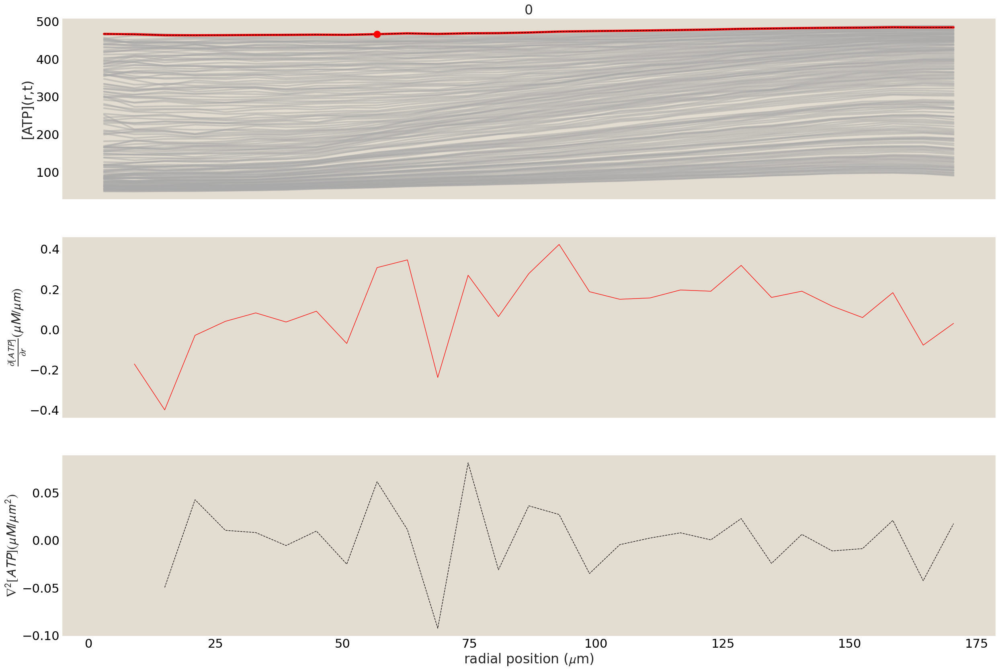

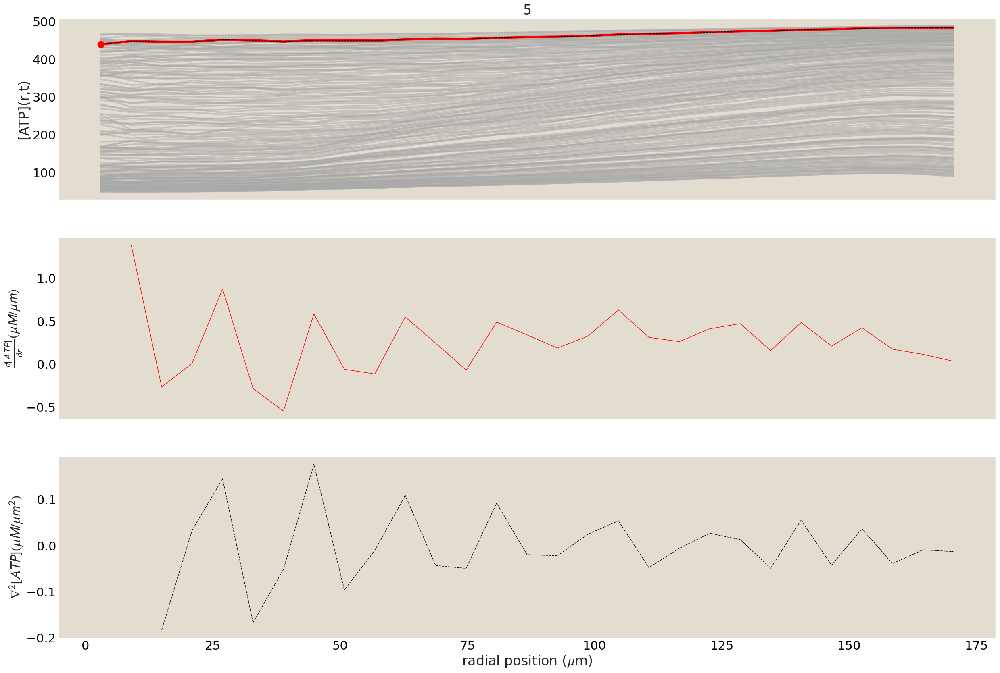

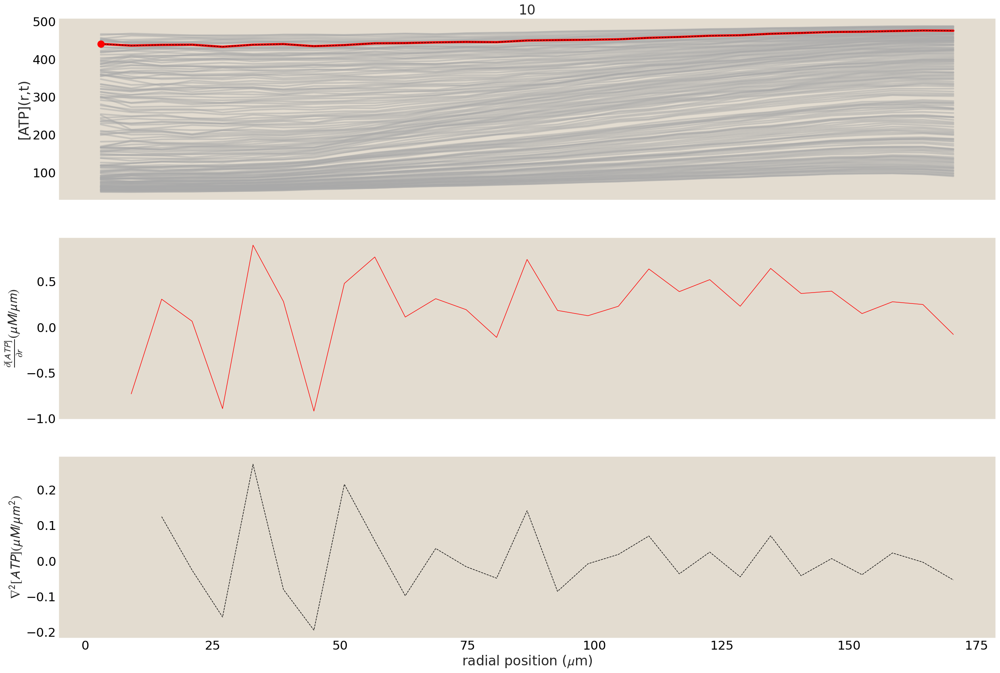

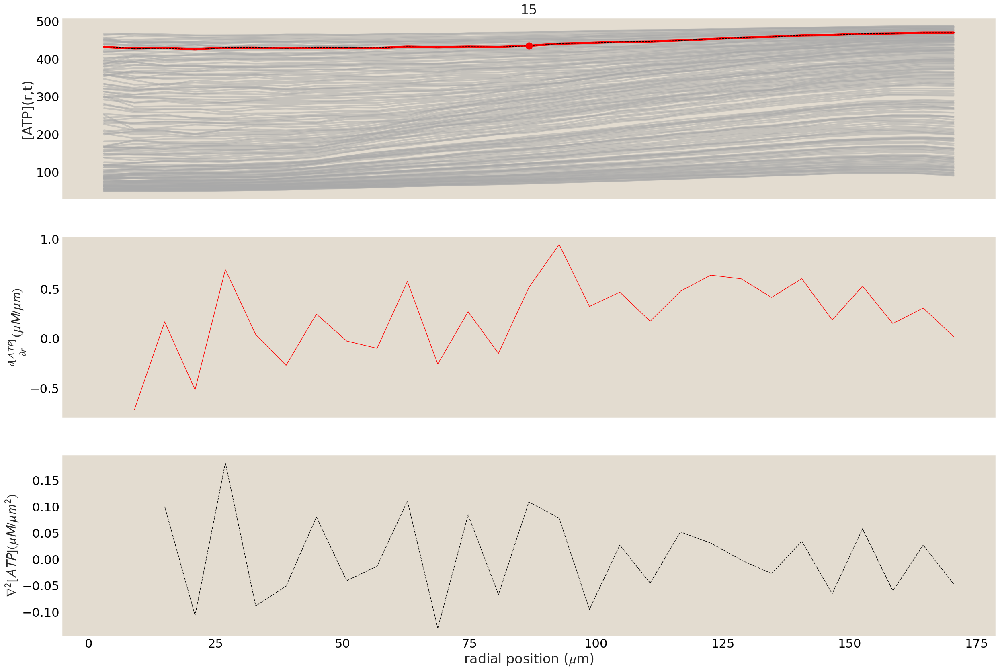

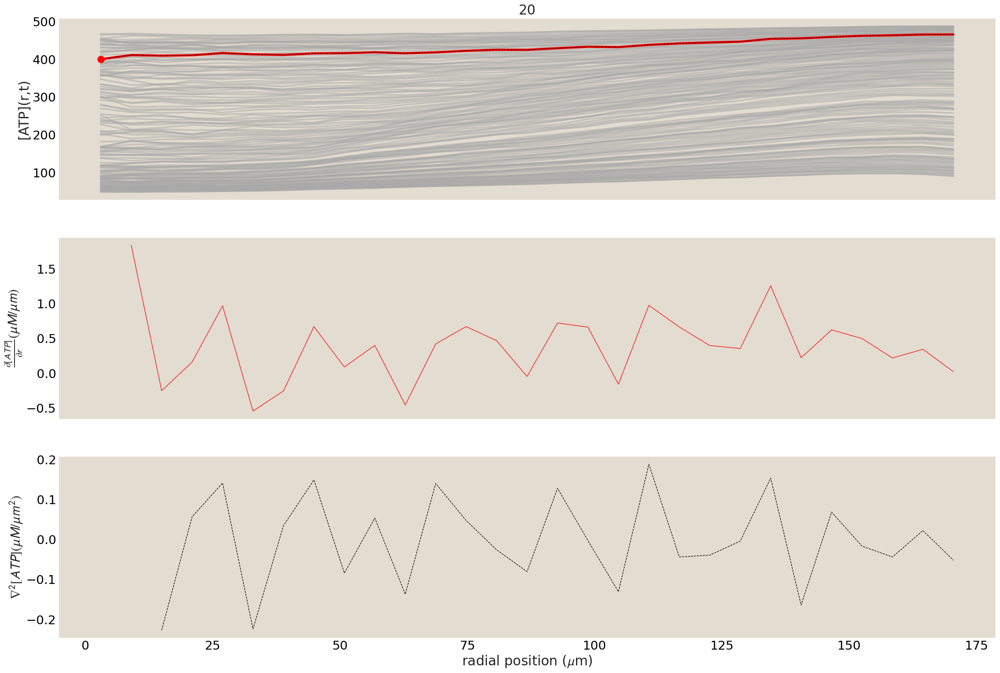

...

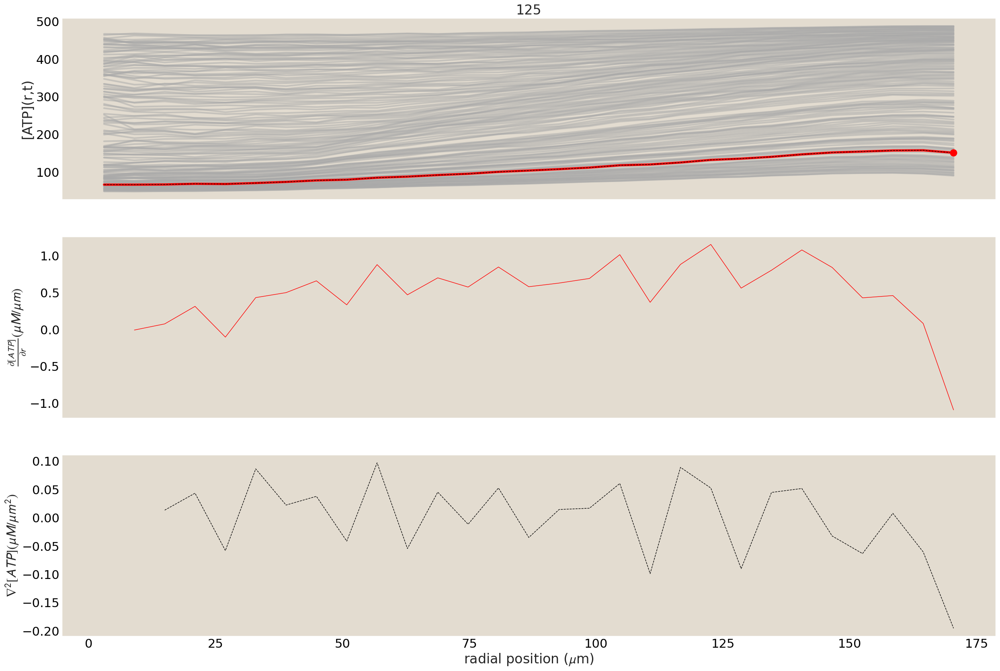

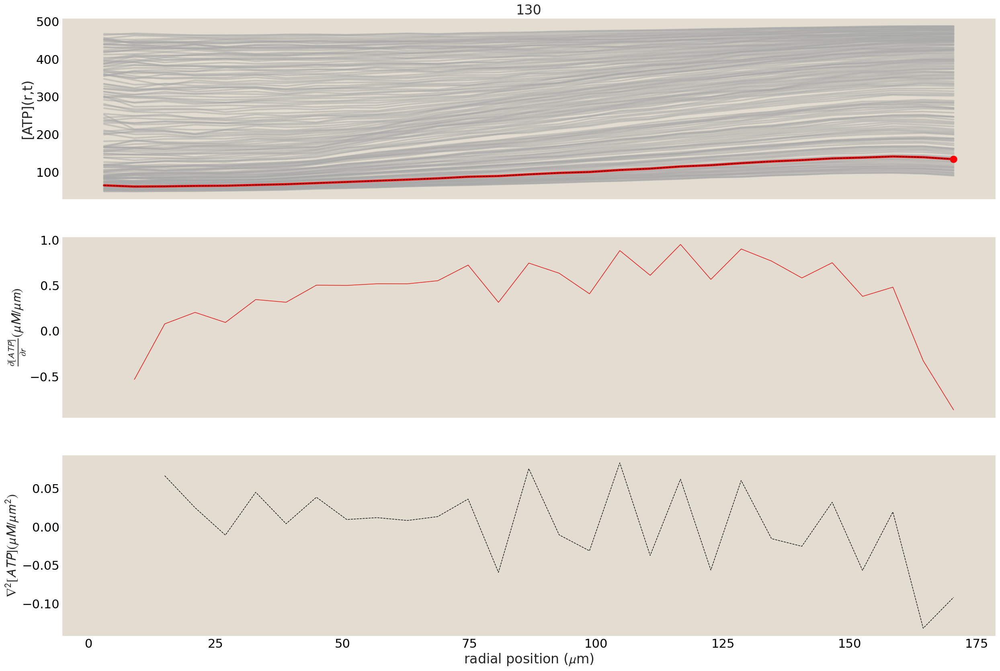

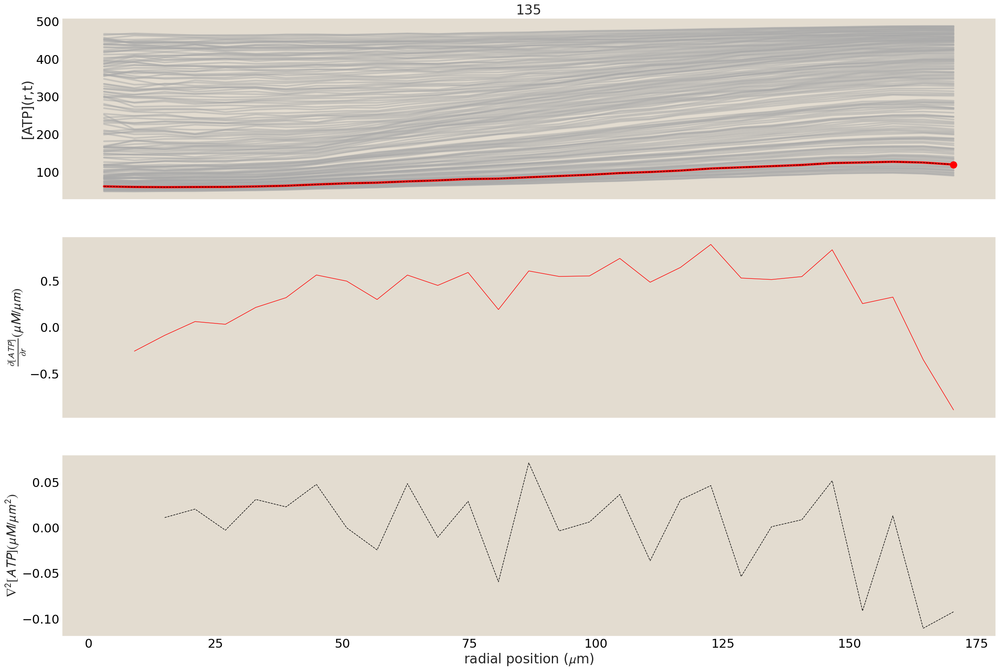

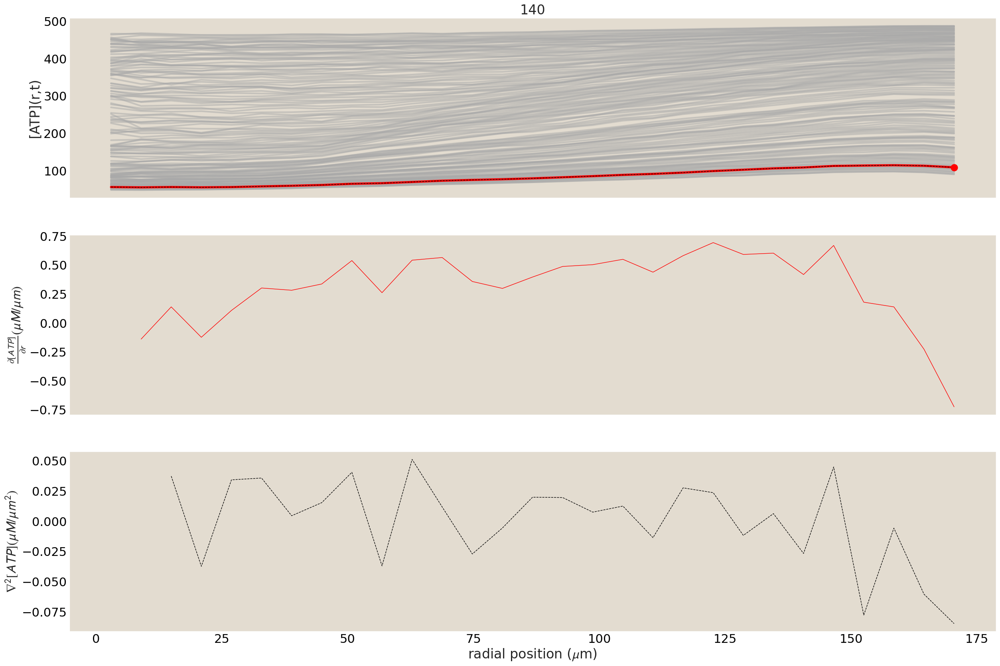

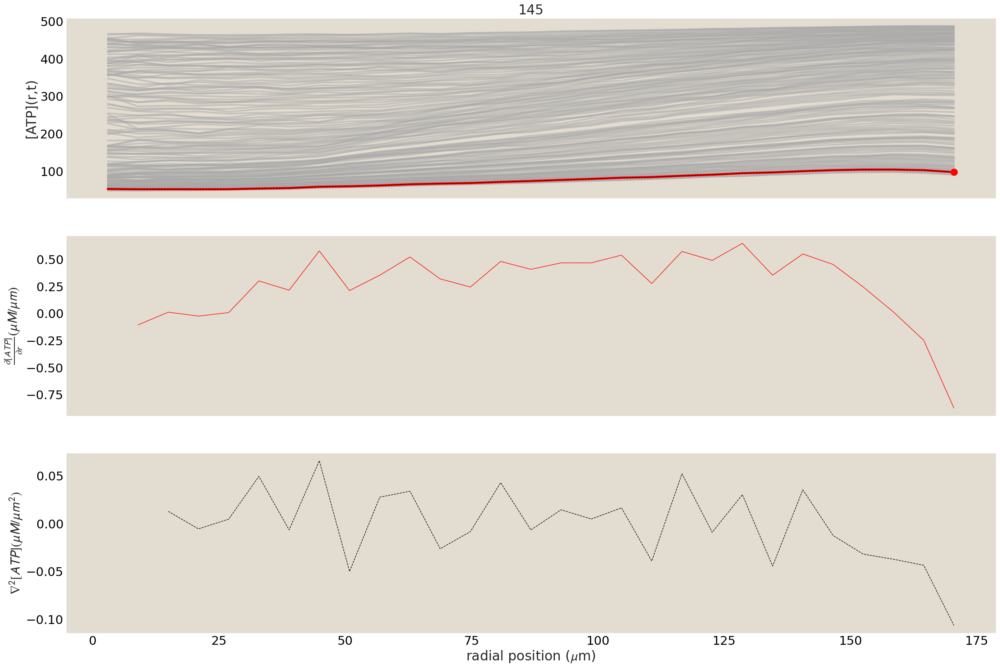

In [138]:
# plot bare data with filtered first
window_length = 5
dr = np.diff(rATPmids[time,:])[0]
for time in range(0, rATPmids.shape[0], 5):
    fig, axs = plt.subplots(nrows=3, figsize=(30,20), sharex=True)
    axs[0].plot(rATPmids[:,:].T,rATPavgs[:,:].T, color='darkgrey', alpha=0.5);  
    axs[0].plot(rATPmids[time,:],
                           rATPavgs[time,:], alpha=1, lw=4,
                           color='red')#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)
    #### FILTERED
    axs[0].plot(rATPmids[time,:], rATPavgs[time,:], lw=1, ls='--', color='k') 
    #axs[0].set_xlabel(r'radial position ($\mu$m)')
    axs[0].set_ylabel(r'[ATP](r,t)')
    axs[0].set_title(str(time))

    ### show first derivative
    #axs[1].plot(rATPmids[time,:], scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=1, delta=np.diff(rATPmids[time,:])[0]), lw=1, ls='--', color='k') 
    #raw 
    axs[1].plot(rATPmids[time,1:], np.diff(rATPavgs[time,:])/dr, lw=1, ls='-', color='r') 
    #axs[1].set_xlabel(r'radial position ($\mu$m)')
    axs[1].set_ylabel(r'$\frac{\partial [ATP]}{\partial r} (\mu M/\mu m)$')    

    # guide to eye on first plot for where gradient is steepest,
    grads=scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=1, delta=np.diff(rATPmids[time,:])[0])
    whereMaxProb=np.where(np.abs(grads)==max(np.abs(grads)))[0][0]
    axs[0].plot(rATPmids[time,whereMaxProb],rATPavgs[time,whereMaxProb], 'ro')

    ### show laplacian
    lap=scipy.signal.savgol_filter(rATPmids[time,:]*rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=2, delta=np.diff(rATPmids[time,:])[0])/rATPmids[time,:];
    #axs[2].plot(rATPmids[time,:], lap, lw=1, ls='--', color='k') 
    #raw
    axs[2].plot(rATPmids[time,2:], np.diff(rATPmids[time,1:]*np.diff(rATPavgs[time,:])/dr)/dr/rATPmids[time,2:], lw=1, ls='--', color='k') 
    axs[2].set_xlabel(r'radial position ($\mu$m)')
    axs[2].set_ylabel(r'$\nabla^2 [ATP] (\mu M/\mu m^2)$')        

plt.show()

### zoom into gradients and apparent curvatures
* In spherical coordinates, the radial part of the laplacian $\nabla^2 c(r,t)$ is
\begin{align}
\nabla^2_r c(r,t) & =  \frac{1}{r^2} \frac{\partial}{\partial r} \left(r^2 \frac{\partial c}{\partial r} \right)\\
& = \frac{1}{r} \frac{\partial^2}{\partial r^2} (r ~ c(r,t)).
\end{align}   

In [121]:
# this is (numTimes, numRbinMidpoints)
rMotmids=h5dic_pc['all_rMotbins']*um_per_pixel
rMotavgs=h5dic_pc['all_rMotavgs']
timesMot=h5dic_pc['timesMot']

rATPmids=h5dic_pc['all_rATPbins']*6*um_per_pixel #*6 bcause of downsampling
rATPavgs=h5dic_pc['all_rATPavgs']
timesATP=h5dic_pc['timesATP']

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/3351186353.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(nrows=3, figsize=(30,20), sharex=True)


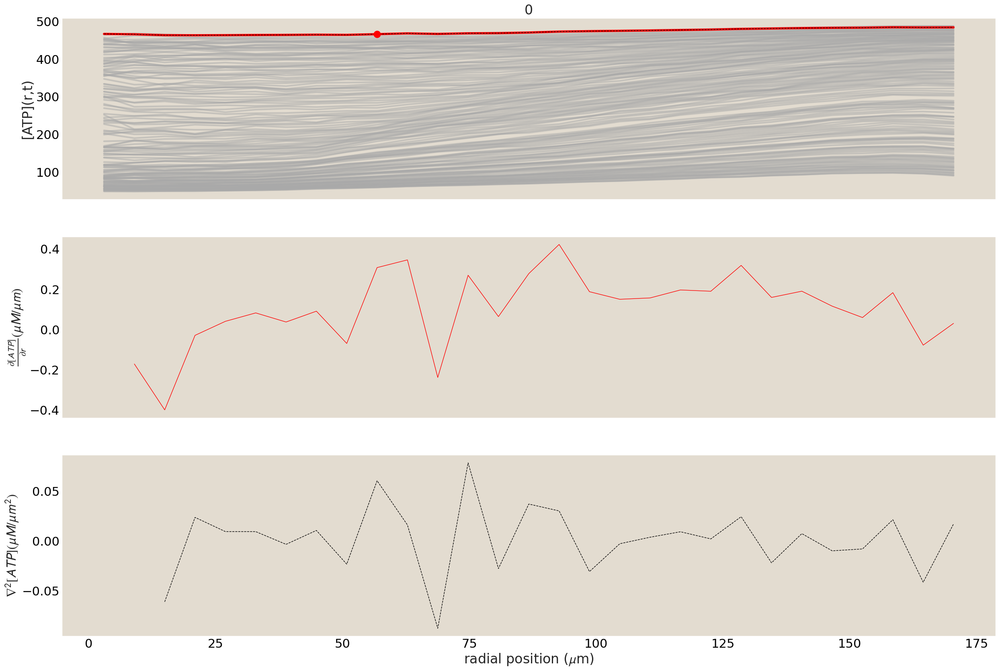

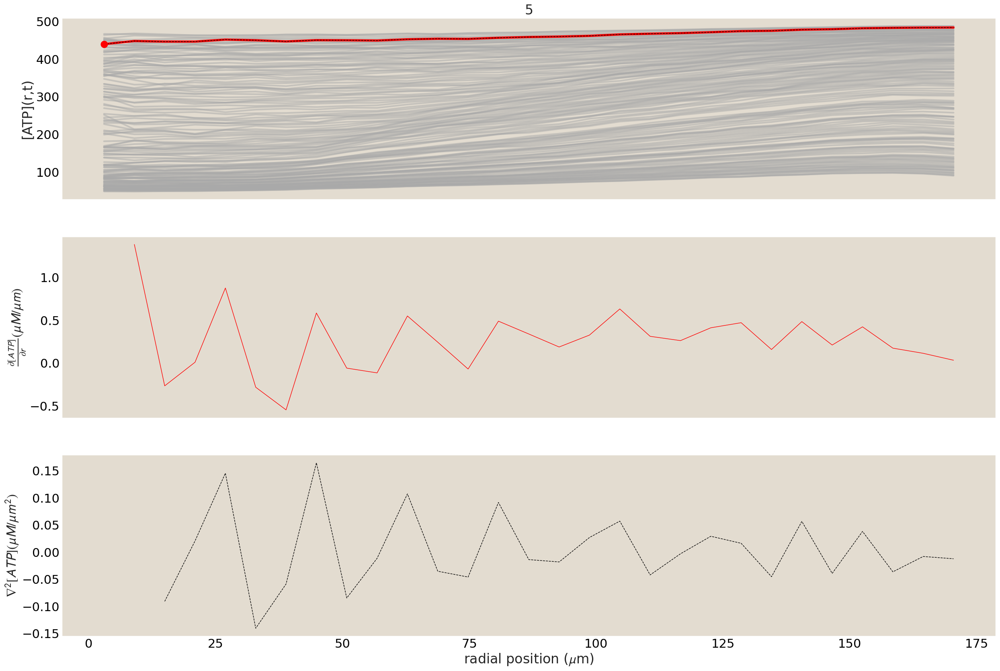

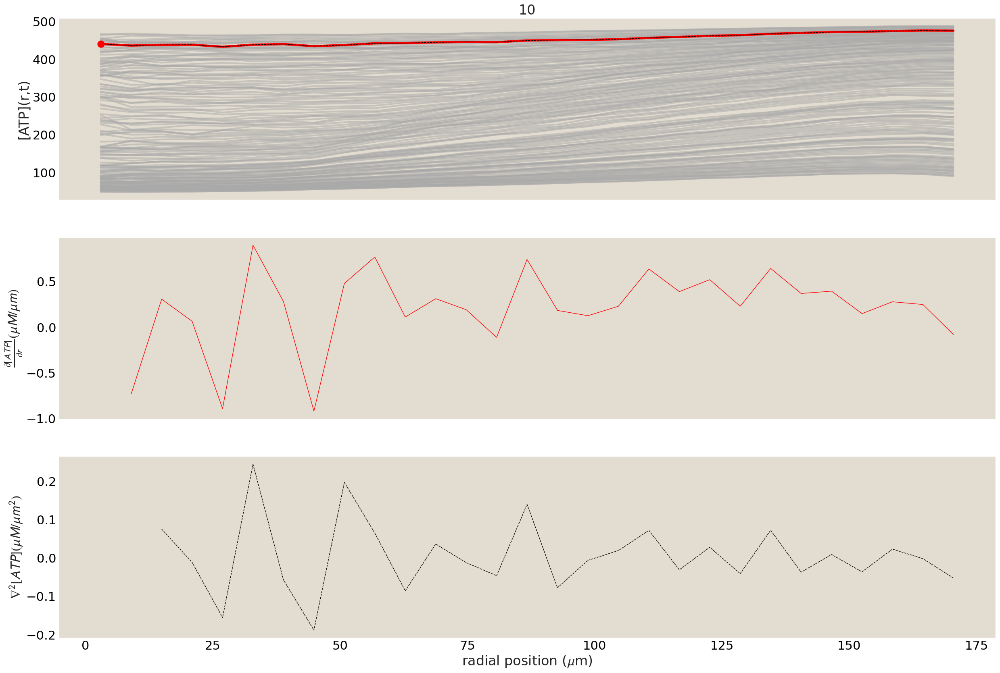

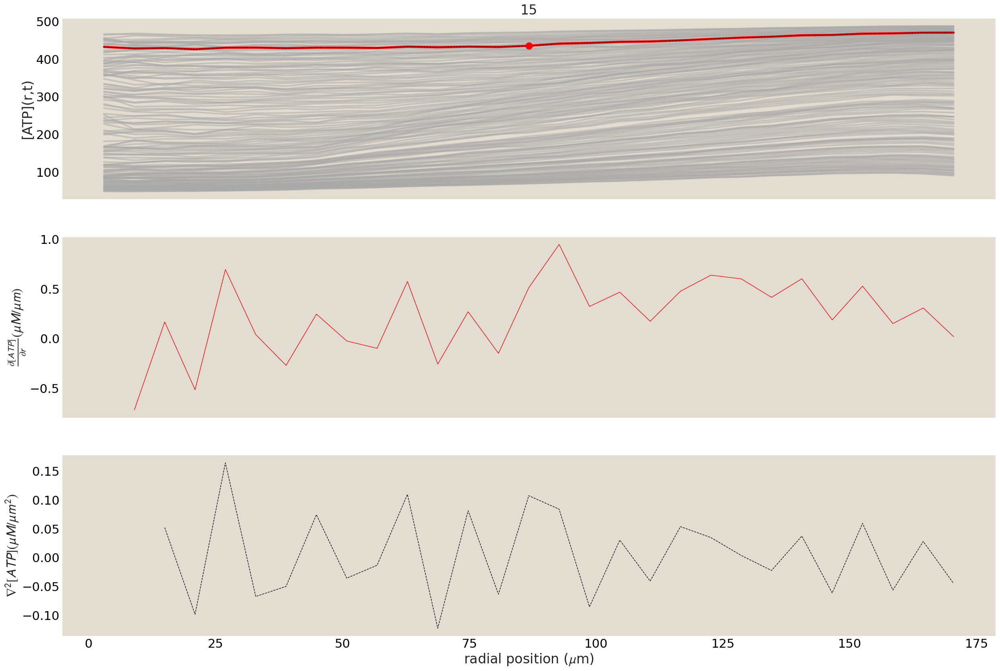

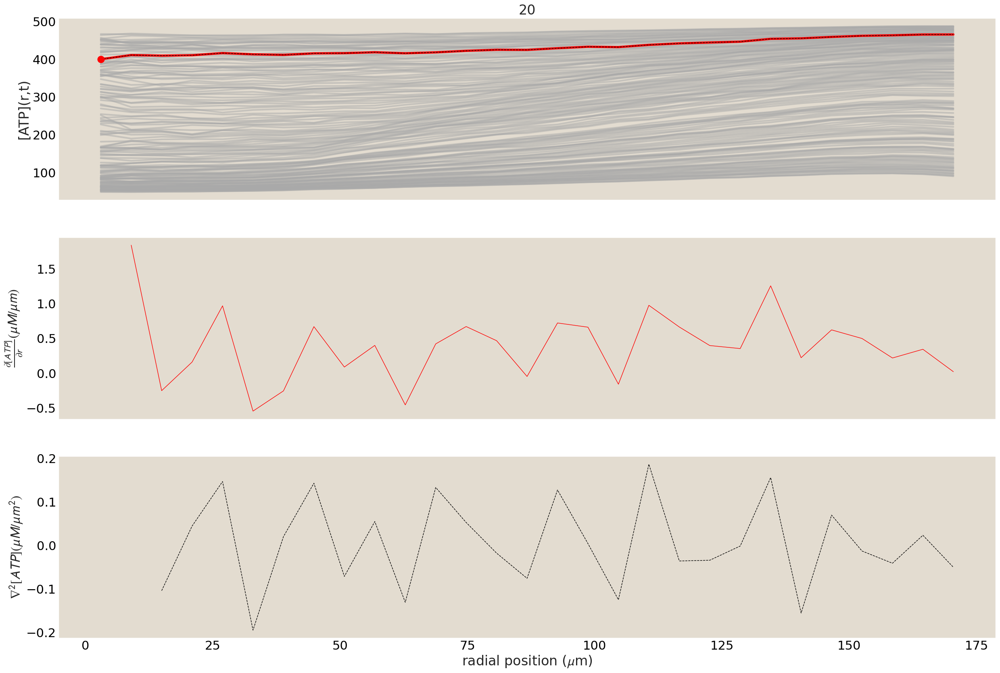

...

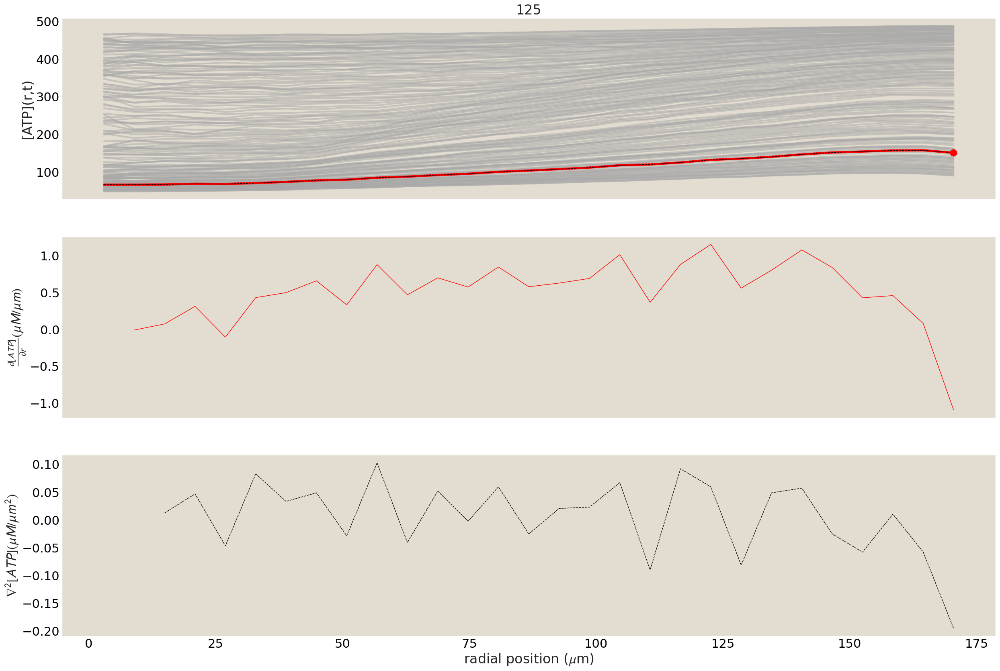

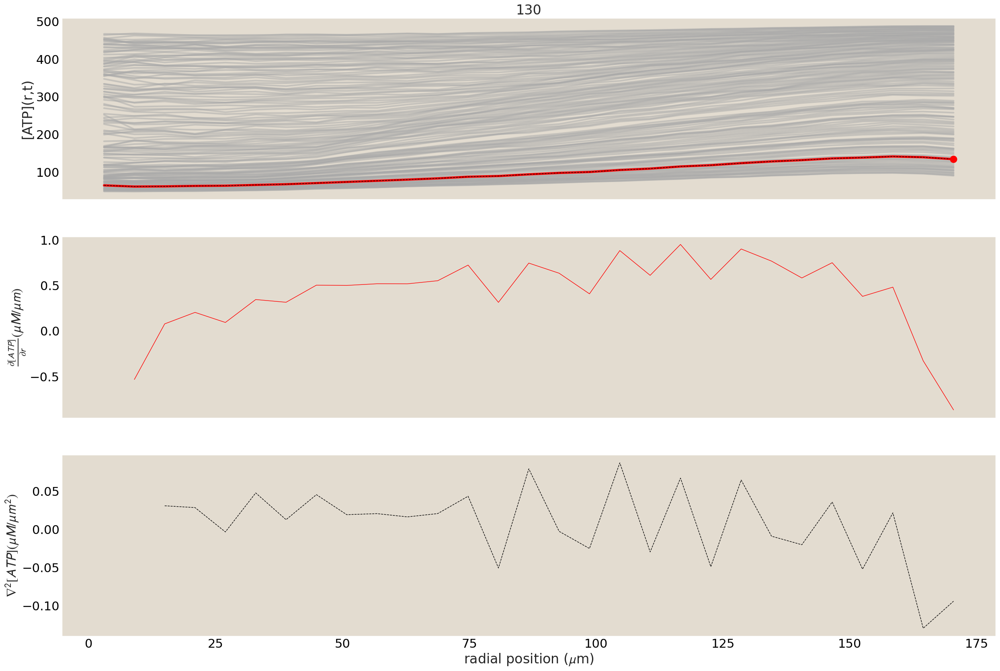

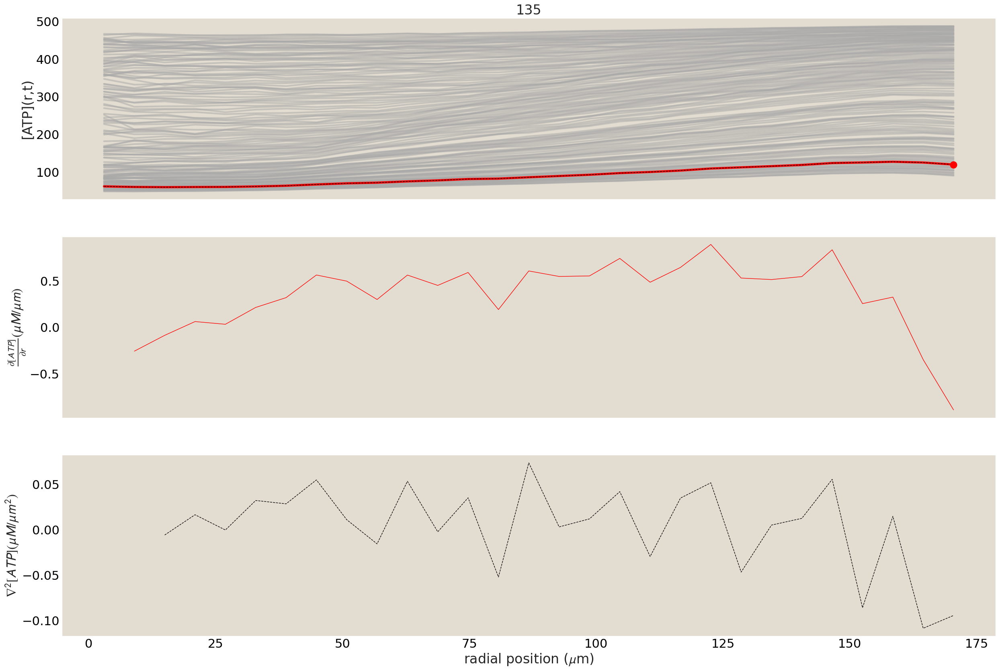

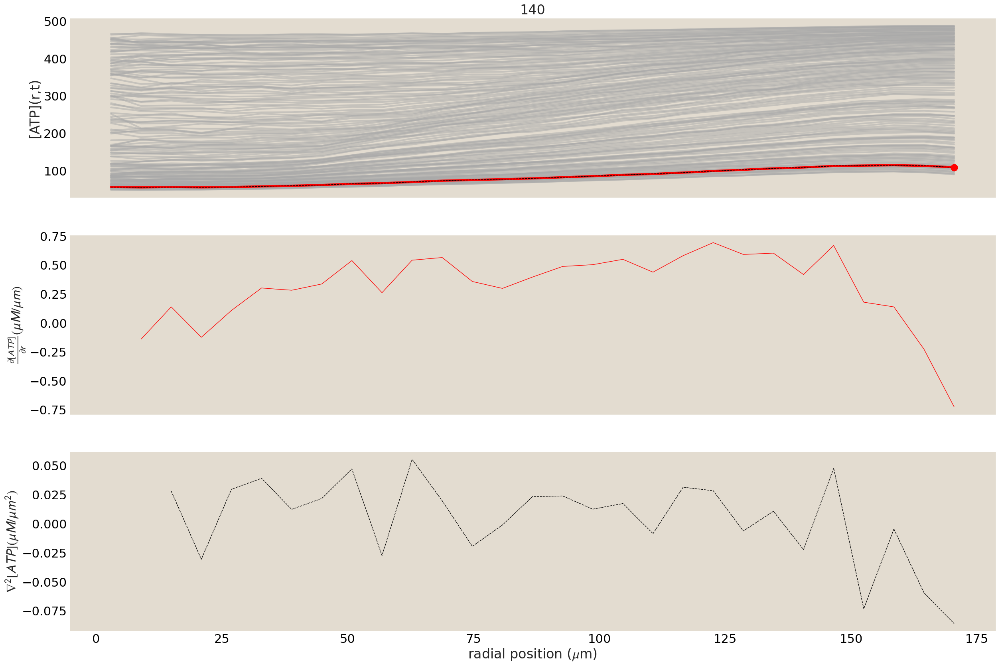

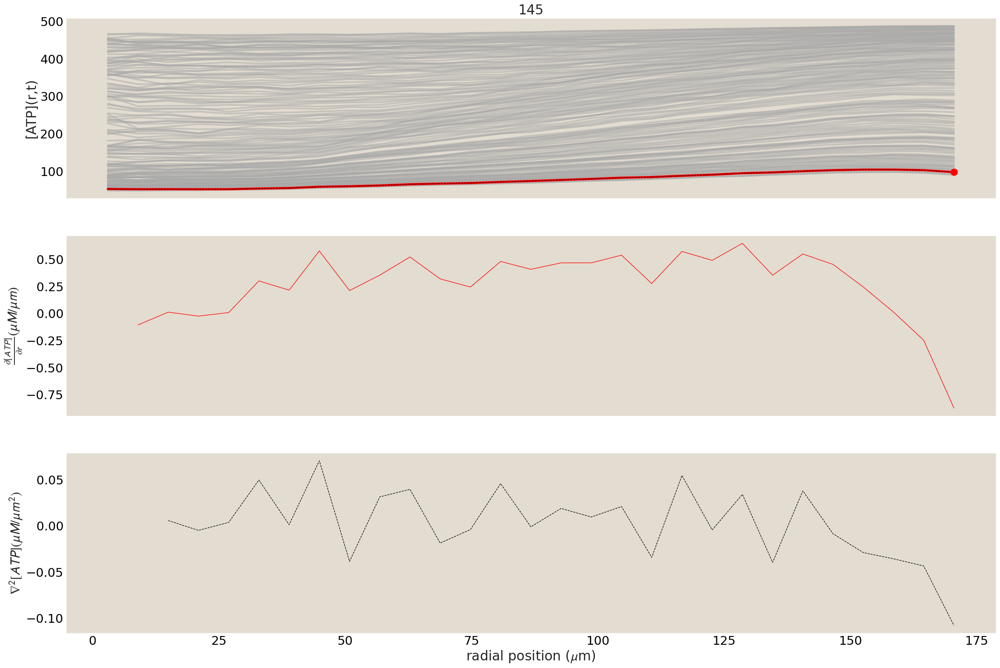

In [137]:
# plot bare data with filtered first
window_length = 5
dr = np.diff(rATPmids[0,:])[0]
for time in range(0, rATPmids.shape[0], 5):
    fig, axs = plt.subplots(nrows=3, figsize=(30,20), sharex=True)
    axs[0].plot(rATPmids[:,:].T,rATPavgs[:,:].T, color='darkgrey', alpha=0.5);  
    axs[0].plot(rATPmids[time,:],
                           rATPavgs[time,:], alpha=1, lw=4,
                           color='red')#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)
    #### FILTERED
    axs[0].plot(rATPmids[time,:], rATPavgs[time,:], lw=1, ls='--', color='k') 
    #axs[0].set_xlabel(r'radial position ($\mu$m)')
    axs[0].set_ylabel(r'[ATP](r,t)')
    axs[0].set_title(str(time))

    ### show first derivative
    #axs[1].plot(rATPmids[time,:], scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=1, delta=np.diff(rATPmids[time,:])[0]), lw=1, ls='--', color='k') 
    #raw 
    axs[1].plot(rATPmids[time,1:], np.diff(rATPavgs[time,:])/dr, lw=1, ls='-', color='r') 
    #axs[1].set_xlabel(r'radial position ($\mu$m)')
    axs[1].set_ylabel(r'$\frac{\partial [ATP]}{\partial r} (\mu M/\mu m)$')    

    # guide to eye on first plot for where gradient is steepest,
    grads=scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=1, delta=np.diff(rATPmids[time,:])[0])
    whereMaxProb=np.where(np.abs(grads)==max(np.abs(grads)))[0][0]
    axs[0].plot(rATPmids[time,whereMaxProb],rATPavgs[time,whereMaxProb], 'ro')

    ### show laplacian
    lap=scipy.signal.savgol_filter(rATPmids[time,:]*rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=2, delta=np.diff(rATPmids[time,:])[0])/rATPmids[time,:];
    #axs[2].plot(rATPmids[time,:], lap, lw=1, ls='--', color='k') 
    #raw
    axs[2].plot(rATPmids[time,2:], np.diff(np.diff(rATPmids[time,:]*rATPavgs[time,:])/dr)/dr/rATPmids[time,2:], lw=1, ls='--', color='k') 
    axs[2].set_xlabel(r'radial position ($\mu$m)')
    axs[2].set_ylabel(r'$\nabla^2 [ATP] (\mu M/\mu m^2)$')        

plt.show()

/home/aduarte/am_atp/analysis/aster/ipykernel_40393/649367753.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(nrows=3, figsize=(30,20), sharex=True)


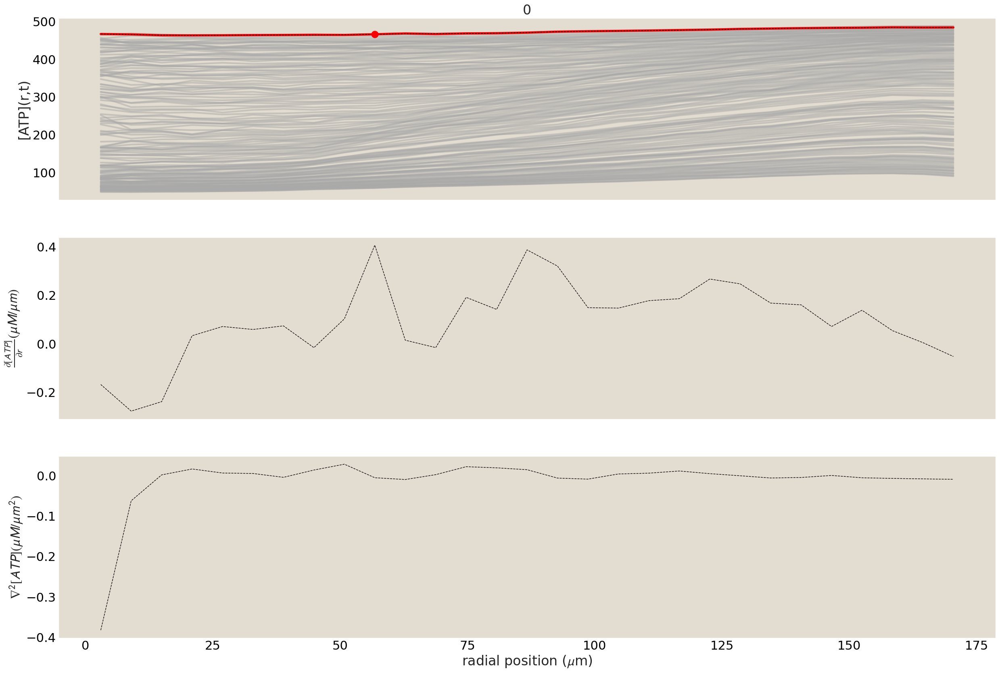

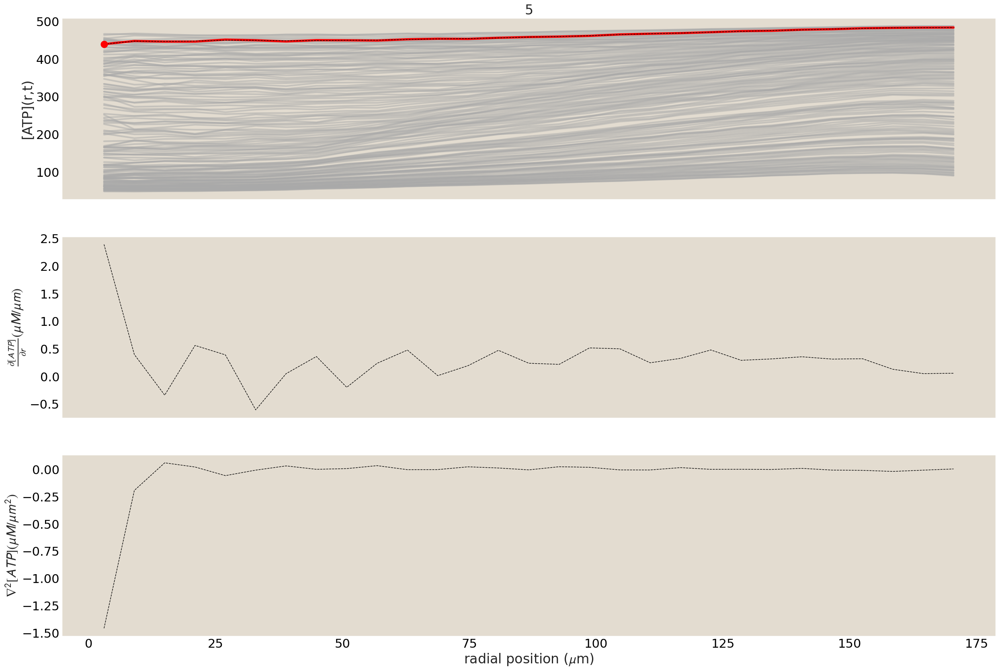

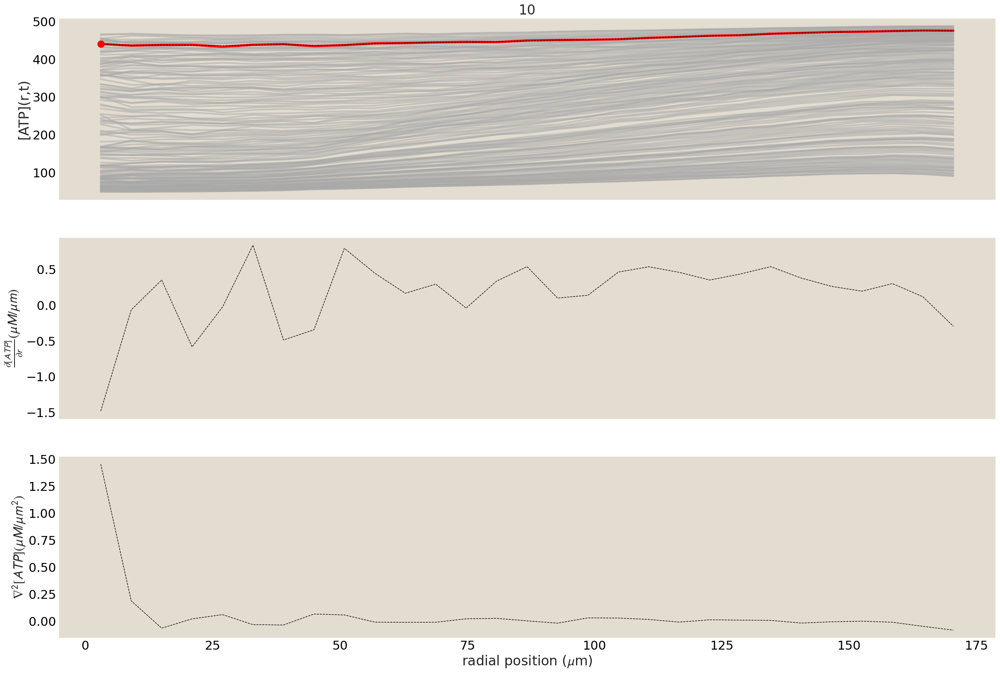

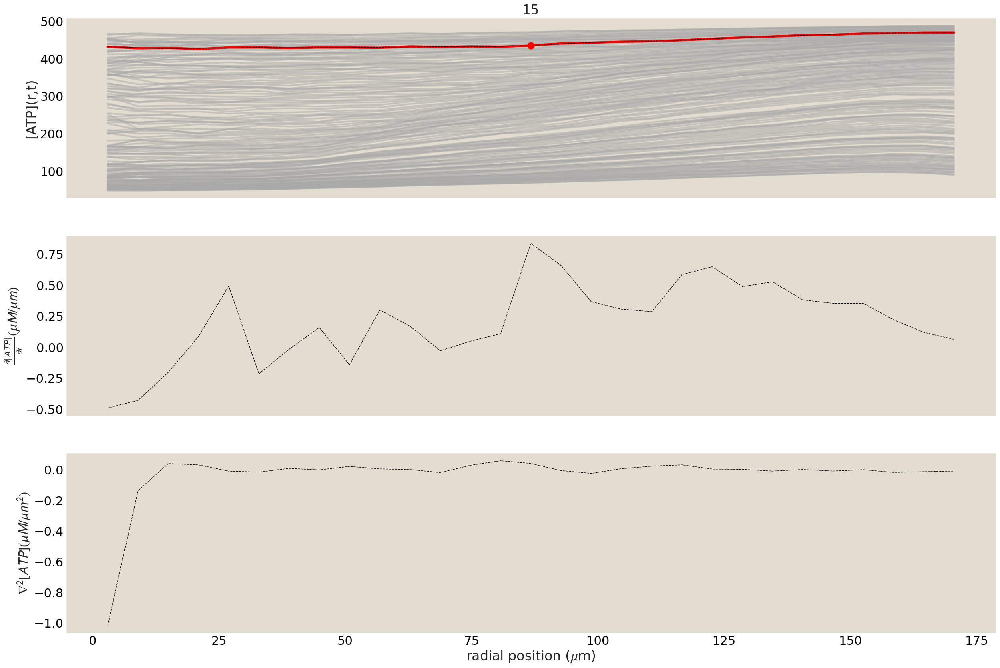

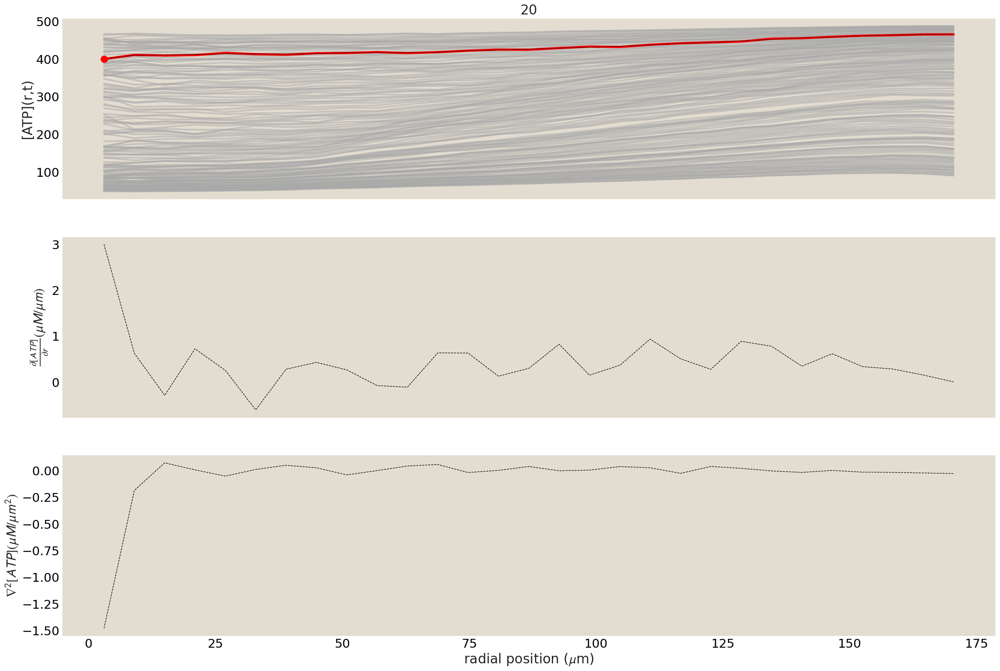

...

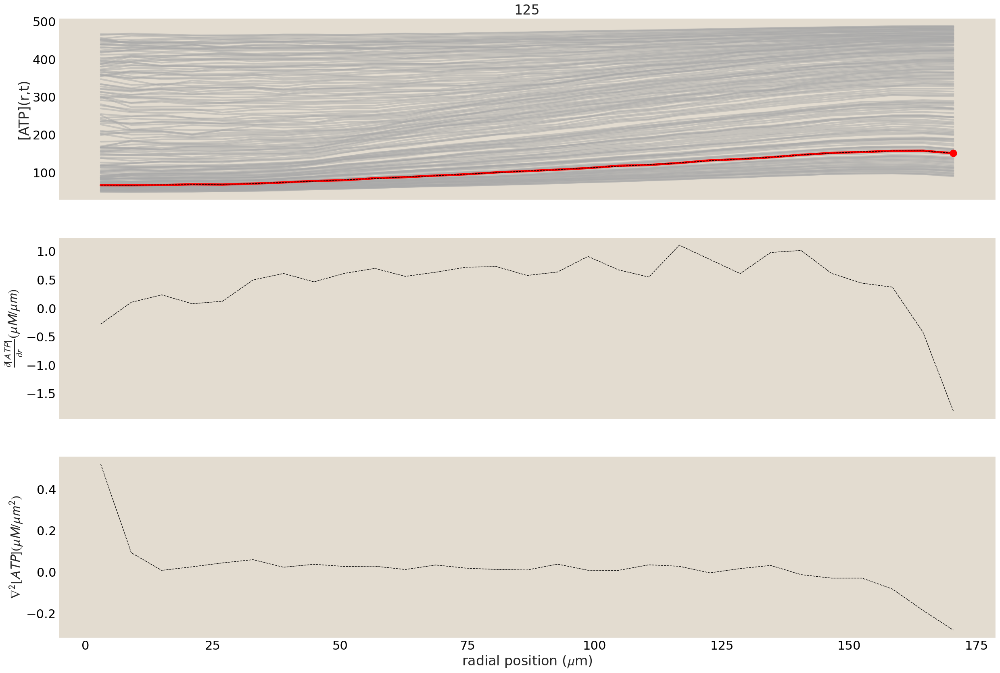

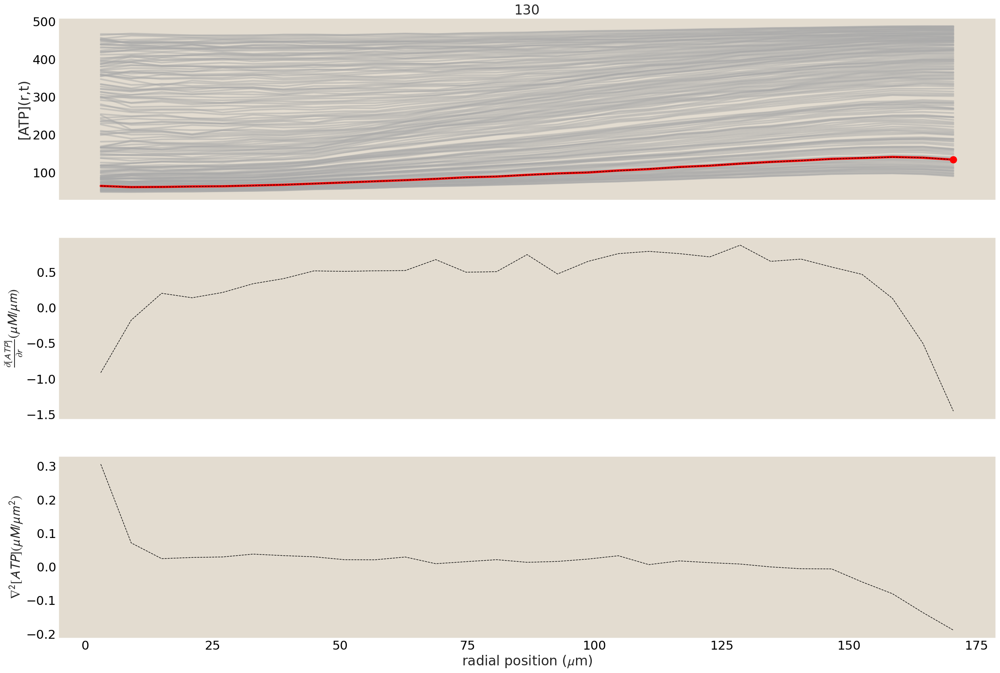

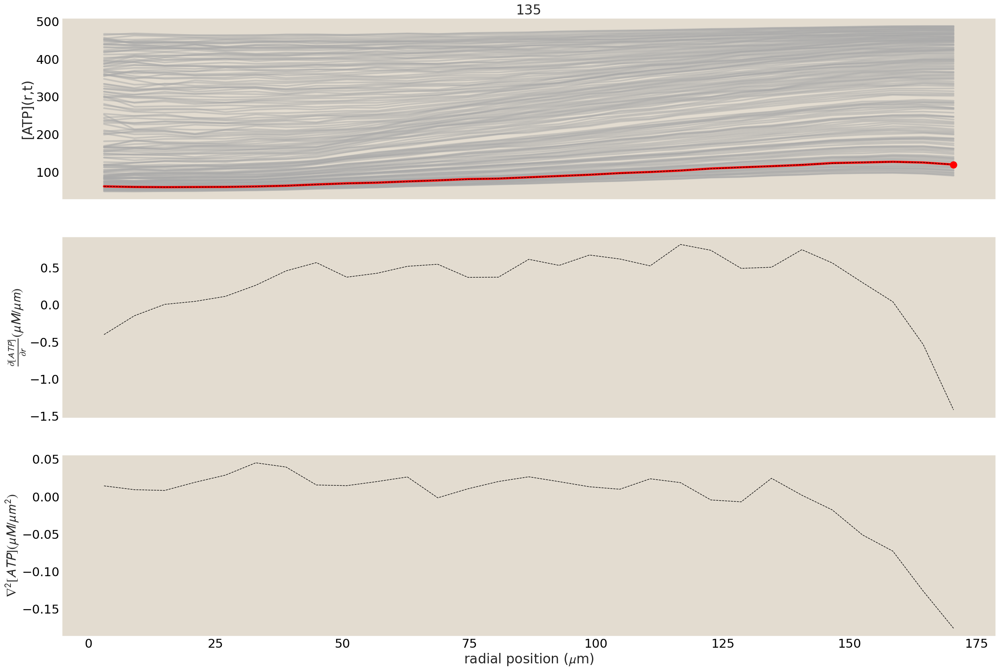

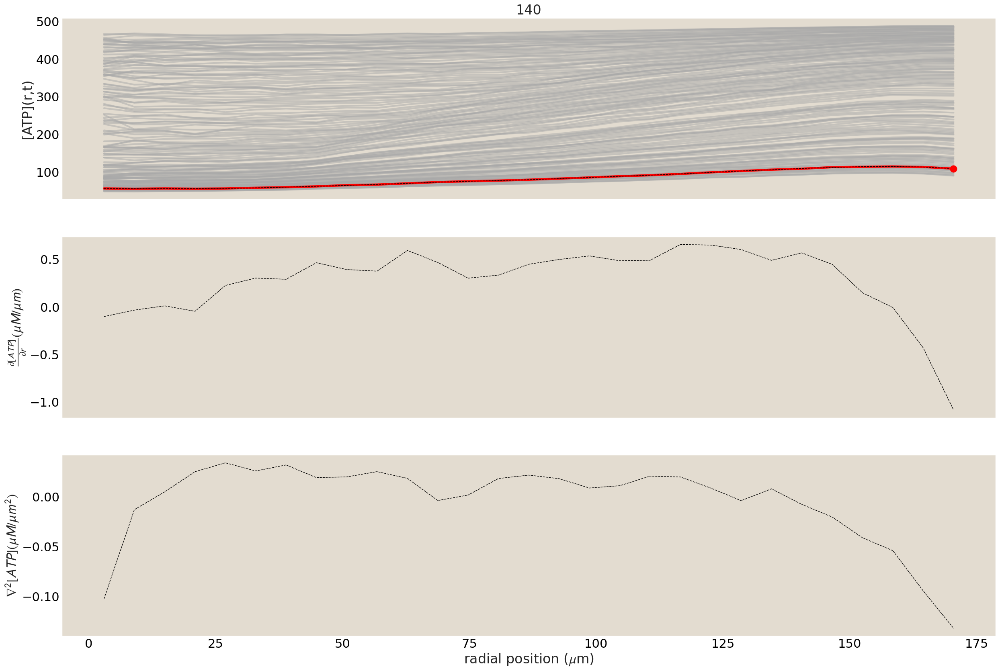

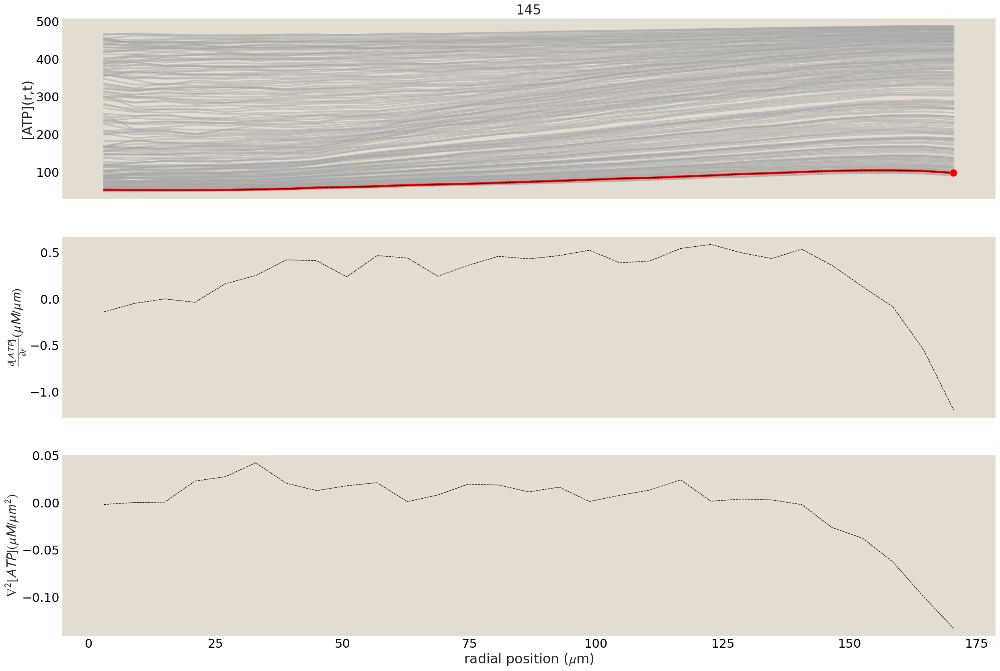

In [129]:
# plot bare data with filtered first
window_length = 5

for time in range(0, rATPmids.shape[0], 5):
    fig, axs = plt.subplots(nrows=3, figsize=(30,20), sharex=True)
    axs[0].plot(rATPmids[:,:].T,rATPavgs[:,:].T, color='darkgrey', alpha=0.5);  
    axs[0].plot(rATPmids[time,:],
                           rATPavgs[time,:], alpha=1, lw=4,
                           color='red')#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)
    #### FILTERED
    axs[0].plot(rATPmids[time,:], scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=0, delta=np.diff(rATPmids[time,:])[0]), lw=1, ls='--', color='k') 
    #axs[0].set_xlabel(r'radial position ($\mu$m)')
    axs[0].set_ylabel(r'[ATP](r,t)')
    axs[0].set_title(str(time))

    ### show first derivative
    axs[1].plot(rATPmids[time,:], scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=1, delta=np.diff(rATPmids[time,:])[0]), lw=1, ls='--', color='k') 
    #raw 
    #axs[1].plot(rATPmids[time,1:], np.diff(rATPavgs[time,:]), lw=1, ls='-', color='r') 
    #axs[1].set_xlabel(r'radial position ($\mu$m)')
    axs[1].set_ylabel(r'$\frac{\partial [ATP]}{\partial r} (\mu M/\mu m)$')    

    # guide to eye on first plot for where gradient is steepest,
    grads=scipy.signal.savgol_filter(rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=1, delta=np.diff(rATPmids[time,:])[0])
    whereMaxProb=np.where(np.abs(grads)==max(np.abs(grads)))[0][0]
    axs[0].plot(rATPmids[time,whereMaxProb],rATPavgs[time,whereMaxProb], 'ro')

    ### show laplacian
    lap=scipy.signal.savgol_filter(rATPmids[time,:]*rATPavgs[time,:], window_length=window_length, polyorder=3, deriv=2, delta=np.diff(rATPmids[time,:])[0])/rATPmids[time,:];
    axs[2].plot(rATPmids[time,:], lap, lw=1, ls='--', color='k') 
    axs[2].set_xlabel(r'radial position ($\mu$m)')
    axs[2].set_ylabel(r'$\nabla^2 [ATP] (\mu M/\mu m^2)$')        

plt.show()

# $\textcolor{red}{\text{end}}$

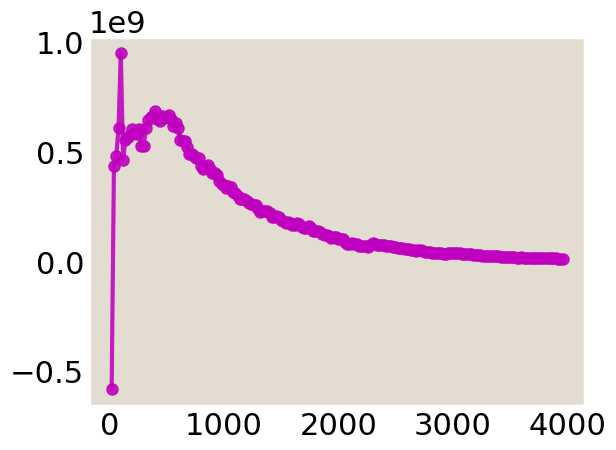

In [53]:
totalPowers_pc=np.sum(h5dic_pc['powerShells'], axis=1)
smoothwindow=5
totalPowers_pc=float_avg(totalPowers_pc, smoothwindow)
times_power_pc=h5dic_pc['timesPower']
plt.plot(times_power_pc, totalPowers_pc, 'o-', ms=8, color='m', label='power', lw=3, alpha=0.88)


In [50]:
sampleKeys = [(500.0, 2.8, 1.3, 150.0, 160.0, '20s', 20.0,  2, 2, '02_06_2025'),
              (500.0, 2.8, 1.3, 150.0, 160.0, '20s', 20.0,  3, 1, '02_06_2025'),
              (500.0, 2.8, 1.3, 150.0, 160.0, '20s', 20.0,  1, 0, '02_06_2025'),
              (500.0, 2.8, 1.3, 150.0, 160.0, '20s', 20.0,   2, 2, '02_11_2025'),
              (500.0, 2.8, 1.3, 150.0, 160.0, '20s', 20.0,  3, 0, '02_11_2025'),
             'mean',
             'median',
             'line fit']
pbocEsqueColorDict={'blue':'#607BB4',
'purple':"#AB85AC",
'green':"#7AA974",
'yellow':'#EAC264',
'reddish':'#D56C55'}
pbocEsqueColorList = ['k', '#607BB4', "#AB85AC", "#7AA974", '#EAC264','#D56C55', 'dimgray', 'gray', 'silver' ]

<>:37: SyntaxWarning: invalid escape sequence '\c'
<>:37: SyntaxWarning: invalid escape sequence '\c'
/home/aduarte/am_atp/analysis/aster/ipykernel_1239129/2908750211.py:37: SyntaxWarning: invalid escape sequence '\c'
  ax.set_ylabel(f'power ($10^8$ ATP $\cdot$ s$^{-1})$', fontsize=30, color=pbocEsqueColorDict['purple'])


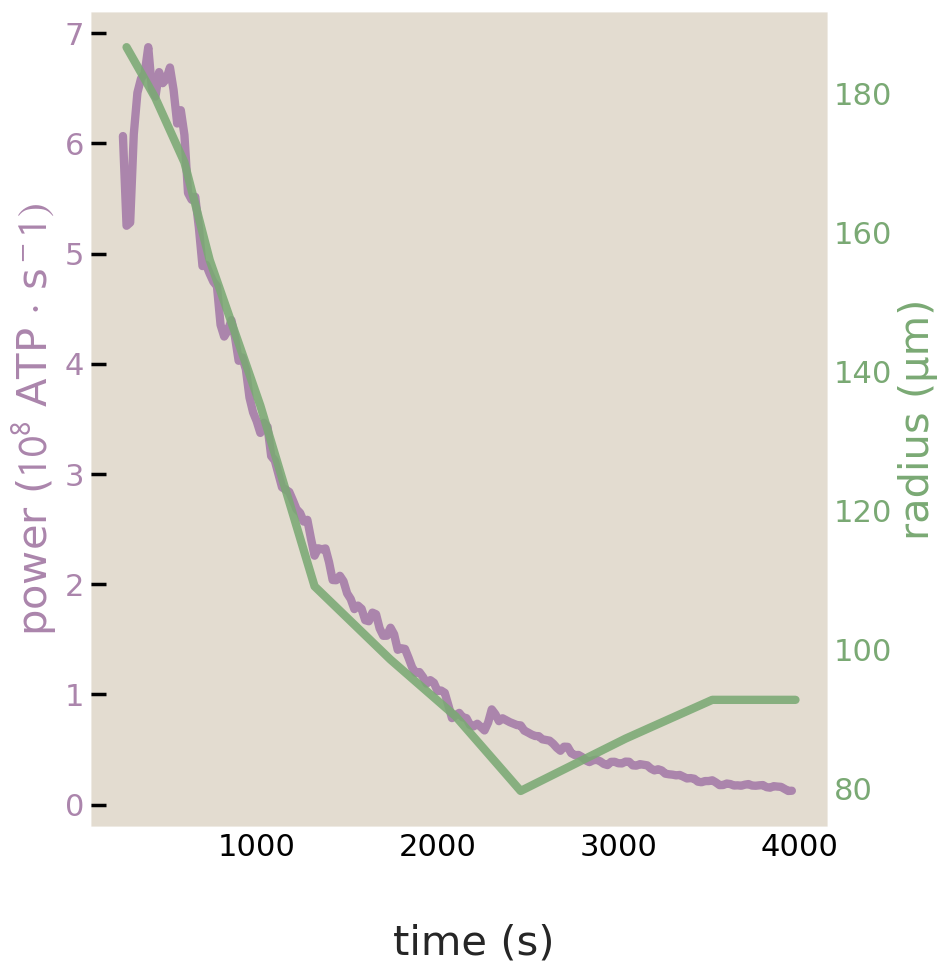

In [54]:
fig, ax = plt.subplots(figsize=(10,10))

plt.plot(times_sec[13:-1], totalPowers_pc[12:]/1e8, color=pbocEsqueColorDict['purple'], lw=6)
#plt.fill_between(times_sec[13:-1], totalPowers_pc[12:]/1e9, color=pbocEsqueColorDict['purple'])
# plt.axhline(3e6/1e9, c='k', lw=1)


ymainticklabels=ax.get_yticklabels()
for label in ymainticklabels:
    label.set_color(pbocEsqueColorDict['purple']) 

centers, axesLengths = cvatCentandRad(gname_pc, 
                                              annotPath, 
                                              imshape = (1200, 1920))
asterRadii = np.sqrt(axesLengths[:,0]*axesLengths[:,1])*um_per_pixel
#times
timesRadii=np.arange(len(asterRadii))*20; #20 seconds interval



twin=ax.twinx()
twin.plot(timesRadii, asterRadii, '-', color=pbocEsqueColorDict['green'], label='power', lw=6, alpha=0.88)
yticklabels=twin.get_yticklabels()
for label in yticklabels:
    label.set_color(pbocEsqueColorDict['green']) 
            # Define the formatter function
# def scientific_notation_formatter(value, tick_number):
#     return r"${:.1g} \times 10^9$".format(value / 1e9)

# # Apply the formatter to the y-axis
# ax.yaxis.set_major_formatter(ticker.FuncFormatter(scientific_notation_formatter))

# Remove y-axis tick lines while keeping the labels
twin.tick_params(axis='y', which='both', length=0)  # Set tick line length to 0


ax.set_ylabel(f'power ($10^8$ ATP $\cdot$ s$^{-1})$', fontsize=30, color=pbocEsqueColorDict['purple'])
fig.supxlabel('time (s)', fontsize=30)

twin.set_ylabel(r'radius (µm)', fontsize=30, color=pbocEsqueColorDict['green'])

plt.tight_layout()

#plt.savefig('20250629_samplePowandRad_12-11-2023_r1_Pos2.pdf', bbox_inches='tight')
